# UNETI15 · AI04 — Nhận biết trạng thái phòng hỗ trợ tiết kiệm điện

**Mục tiêu:** giảm lỗi nhận nhầm phòng đang có người thành phòng trống và kiểm chứng điều kiện khuyến nghị bằng dữ liệu cảm biến.

**Quy trình:** EDA → Baseline Logistic BTC → Cải tiến Logistic → So sánh cùng điều kiện → Phân tích lỗi → Cải tiến cảnh báo.

Chỉ dùng **Temperature, Humidity, Light, CO2, HumidityRatio** làm đầu vào mô hình. `date` chỉ dùng cho phân tích, chia dữ liệu và kiểm tra chuỗi; ID và nhãn không phải đặc trưng.

- Chọn cấu hình bằng hai quy trình CV **bên trong datatraining.txt**; giữ nguyên 16 cấu hình, seed và quy tắc xếp hạng nghiên cứu gốc.
- So sánh cuối cùng trên **datatest.txt**. Validation đã từng được xem trong quá trình nghiên cứu; đây không phải tập đánh giá hoàn toàn chưa tiếp xúc. Không điều chỉnh cấu hình theo các lỗi validation trong notebook này.
- Không đọc `datatest2.txt`. Dữ liệu gốc từ phòng làm việc UCI, chưa được xác thực tại lớp học UNETI.
- Chạy **Restart Kernel → Run All**. `results/` chỉ xuất các bảng và hình chọn lọc để nộp; mô hình tái lập ở trong bộ nhớ. Hai mô hình và metadata của ứng dụng được bảo vệ bằng SHA-256.

Đề AI04 yêu cầu cải tiến **mô hình hoặc logic cảnh báo**, không bắt buộc so sánh nhiều họ thuật toán. Notebook tập trung baseline Logistic và cải tiến Logistic; các cấu hình nghiên cứu không phải mô hình được thêm vào ứng dụng.

In [1]:
# Bước 01
# 1. Thu vien Python co ban
import sys
import json
import time
import platform
import warnings
import hashlib
from IPython.display import display

from pathlib import Path
from importlib.metadata import version

# 2. Xu ly du lieu
import numpy as np
import pandas as pd

# 3. Truc quan hoa
import matplotlib.pyplot as plt

# 4. Luu va tai model
import joblib

# 5. Thong ke


# 6. Cross-Validation
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedGroupKFold
)

# 7. Tien xu ly
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures
)

# 8. Cac mo hinh Machine Learning
from sklearn.linear_model import LogisticRegression

# 9. Danh gia mo hinh
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 10. Cau hinh tai lap
SEED = 2026
np.random.seed(SEED)

# 11. Cau hinh pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.6f}".format)

# Bộ định dạng biểu đồ tiếng Việt được nạp sau khi xác định ROOT.

# 13. Kiem tra moi truong
print("=" * 60)
print("SMART CAMPUS AI - ENVIRONMENT CHECK")
print("=" * 60)

print("Python       :", sys.version.split()[0])
print("Platform     :", platform.system())
print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("Scikit-learn :", version("scikit-learn"))
print("Matplotlib   :", version("matplotlib"))
print("Random seed  :", SEED)


SMART CAMPUS AI - ENVIRONMENT CHECK
Python       : 3.11.5
Platform     : Windows
NumPy        : 1.26.4
Pandas       : 2.2.3
Scikit-learn : 1.6.1
Matplotlib   : 3.10.7
Random seed  : 2026


In [2]:
# Bước 02
# 1. Tim thu muc goc du an
ROOT = None

current_path = Path.cwd().resolve()

for folder in [current_path, *current_path.parents]:

    expected_data = (
        folder / "data" / "AI04" / "datatraining.txt"
    )

    if expected_data.is_file():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "Khong tim thay data/AI04/datatraining.txt. "
        "Hay mo dung thu muc du an UNETI15."
    )

# 2. Cau hinh cac thu muc
DATA_DIR = ROOT / "data" / "AI04"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
MODEL_DIR = ROOT / "model"
BTC_OUTPUT_DIR = ROOT / "outputs" / "AI04"

# 3. Tao thu muc luu ket qua neu can
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 4. Duong dan cac file du lieu
TRAIN_PATH = DATA_DIR / "datatraining.txt"
VAL_PATH = DATA_DIR / "datatest.txt"


# 5. Cau hinh bai toan
FEATURES = [
    "Temperature",
    "Humidity",
    "Light",
    "CO2",
    "HumidityRatio"
]

TARGET = "Occupancy"

CLASS_NAMES = {
    0: "Empty",
    1: "Occupied"
}
# 7. Kiem tra file dau vao
assert TRAIN_PATH.is_file(), "Thieu datatraining.txt"
assert VAL_PATH.is_file(), "Thieu datatest.txt"

print("=" * 60)
print("PROJECT CONFIGURATION")
print("=" * 60)

print("ROOT       :", ROOT)
print("DATA       :", DATA_DIR)
print("RESULTS    :", RESULTS_DIR)
print("MODEL      :", MODEL_DIR)
print("BTC OUTPUT :", BTC_OUTPUT_DIR)

print("\nFeatures:", FEATURES)
print("Target  :", TARGET)

# Mô hình tái lập chỉ lưu trong bộ nhớ; results chỉ chứa bộ kết quả nộp bài.
PROTECTED_PATHS = [
    ROOT / "outputs/AI04/model.joblib", ROOT / "model/logistic_optimized.joblib",
    ROOT / "outputs/AI04/metrics.json", ROOT / "model/logistic_optimized_metadata.json",
    ROOT / "model/ai04_app_config.json",
]
def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
protected_before = {p.relative_to(ROOT).as_posix(): sha256_file(p) for p in PROTECTED_PATHS}

# Chung một bộ định dạng cho notebook, PNG và SVG; không cần mạng.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import research_charts as charts
figure_book = charts.FigureBook(FIGURES_DIR)
print("Font biểu đồ:", figure_book.typography["font"])

def save_figure(filename, title, message, fig=None):
    return figure_book.save(fig or plt.gcf(), filename, title, message)

# Chặn việc vô tình đọc tập ngoài phạm vi trong cả phiên kernel.
def _research_data_guard(event, args):
    if event == "open" and args and isinstance(args[0], (str, bytes)):
        name = args[0].decode(errors="replace") if isinstance(args[0], bytes) else args[0]
        if Path(name).name.casefold() == "datatest2.txt":
            raise PermissionError("datatest2.txt nằm ngoài phạm vi nghiên cứu này.")
sys.addaudithook(_research_data_guard)


PROJECT CONFIGURATION
ROOT       : C:\nam4\Nam4\olypic\vong3\UNETI15
DATA       : C:\nam4\Nam4\olypic\vong3\UNETI15\data\AI04
RESULTS    : C:\nam4\Nam4\olypic\vong3\UNETI15\results
MODEL      : C:\nam4\Nam4\olypic\vong3\UNETI15\model
BTC OUTPUT : C:\nam4\Nam4\olypic\vong3\UNETI15\outputs\AI04

Features: ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']
Target  : Occupancy
Font biểu đồ: Segoe UI


## A. EDA — Dữ liệu và tín hiệu

Kiểm tra chất lượng, mất cân bằng nhãn và quan hệ tín hiệu với trạng thái phòng trước khi thiết kế thực nghiệm. Giá trị cảm biến trùng ở nhiều thời điểm có thể là quan sát hợp lệ, không tự động xóa. Các histogram Light/CO₂ chỉ cắt phần đuôi để dễ xem; thống kê và mô hình vẫn dùng dữ liệu gốc.

Đọc dữ liệu huấn luyện

In [3]:
# Bước 03
# 1. Doc du lieu goc
# Cot dau tien trong file UCI la chi so ID.
# index_col=0 giup giu ID lam index thay vi feature.

train_df = pd.read_csv(
    TRAIN_PATH,
    index_col=0
)

# 2. Kiem tra cot bat buoc
required_columns = ["date"] + FEATURES + [TARGET]

missing_columns = [
    column
    for column in required_columns
    if column not in train_df.columns
]

if missing_columns:
    raise ValueError(
        f"Training data thieu cot: {missing_columns}"
    )

# 3. Chuyen cot thoi gian
# Chi phuc vu EDA va chia du lieu.
train_df["date"] = pd.to_datetime(
    train_df["date"],
    errors="coerce"
)

if train_df["date"].isna().any():
    raise ValueError("Training data co thoi gian khong hop le.")

# 4. Chuyen 5 dac trung sang du lieu so
for feature in FEATURES:

    train_df[feature] = pd.to_numeric(
        train_df[feature],
        errors="coerce"
    )

# 5. Kiem tra nhan
if not train_df[TARGET].isin([0, 1]).all():
    raise ValueError(
        "Occupancy chi duoc nhan gia tri 0 hoac 1."
    )

train_df[TARGET] = train_df[TARGET].astype(int)

# 6. Kiem tra gia tri vo cuc
if np.isinf(
    train_df[FEATURES].to_numpy(dtype=float)
).any():
    raise ValueError("Training data chua gia tri vo cuc.")

# 7. Tao du lieu huan luyen
# Chi su dung 5 feature duoc BTC cho phep.

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

# 8. Kiem tra ket qua
print("=" * 60)
print("TRAINING DATA")
print("=" * 60)

print("Shape:", train_df.shape)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nData types:")
print(train_df.dtypes)

print("\nFirst 5 rows:")
display(train_df.head())

print("\nTime range:")
print("Start:", train_df["date"].min())
print("End  :", train_df["date"].max())


TRAINING DATA
Shape: (8143, 7)
X_train: (8143, 5)
y_train: (8143,)

Column names:
['date', 'Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Occupancy']

Data types:
date             datetime64[ns]
Temperature             float64
Humidity                float64
Light                   float64
CO2                     float64
HumidityRatio           float64
Occupancy                 int32
dtype: object

First 5 rows:


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.180000,27.272000,426.000000,721.250000,0.004793,1
2,2015-02-04 17:51:59,23.150000,27.267500,429.500000,714.000000,0.004783,1
3,2015-02-04 17:53:00,23.150000,27.245000,426.000000,713.500000,0.004779,1
4,2015-02-04 17:54:00,23.150000,27.200000,426.000000,708.250000,0.004772,1
5,2015-02-04 17:55:00,23.100000,27.200000,426.000000,704.500000,0.004757,1



Time range:
Start: 2015-02-04 17:51:00
End  : 2015-02-10 09:33:00


Kiểm tra chất lượng dữ liệu và phân bố nhãn

In [4]:
# Bước 04
print("=" * 60)
print("DATA QUALITY ANALYSIS")
print("=" * 60)

# 1. Kiem tra missing values
missing_values = train_df.isna().sum()

print("\n1. MISSING VALUES")
display(missing_values.to_frame("Missing Count"))

# 2. Kiem tra ban ghi trung
duplicate_sensor_count = train_df.duplicated(
    subset=FEATURES
).sum()

duplicate_full_count = train_df.duplicated(
    subset=["date"] + FEATURES + [TARGET]
).sum()

print("\n2. DUPLICATE ANALYSIS")

print("Duplicate sensor values:", duplicate_sensor_count)
print("Duplicate full records :", duplicate_full_count)

# Kiem tra cung mot bo cam bien nhung khac nhan
label_counts_per_sensor = (
    train_df.groupby(FEATURES, dropna=False)[TARGET]
    .nunique()
)

conflicting_sensor_groups = int(
    (label_counts_per_sensor > 1).sum()
)

print("Conflicting sensor groups:", conflicting_sensor_groups)

# Khong tu dong xoa ban ghi trung.
# Du lieu cam bien co the trung gia tri qua nhieu thoi diem.


# 3. Phan bo nhan
class_counts = (
    y_train
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

class_distribution = pd.DataFrame({
    "class": [0, 1],
    "class_name": ["Empty", "Occupied"],
    "samples": class_counts.to_numpy(),
    "percentage": (
        class_counts.to_numpy() / len(y_train) * 100
    )
})

print("\n3. CLASS DISTRIBUTION")
display(class_distribution.round(2))


# 4. Phan bo nhan theo ngay
daily_distribution = (
    train_df
    .groupby(train_df["date"].dt.date)[TARGET]
    .agg(
        total_samples="size",
        occupied_samples="sum"
    )
    .reset_index()
)

daily_distribution.columns = [
    "day",
    "total_samples",
    "occupied_samples"
]

daily_distribution["empty_samples"] = (
    daily_distribution["total_samples"] -
    daily_distribution["occupied_samples"]
)

daily_distribution["occupied_ratio"] = (
    daily_distribution["occupied_samples"] /
    daily_distribution["total_samples"]
)

print("\n4. DAILY CLASS DISTRIBUTION")
display(daily_distribution.round(4))


# 5. Luu thong ke


# 6. Tong hop nhan xet
print("\n5. DATA QUALITY SUMMARY")

print("Total samples:", len(train_df))
print("Missing values:", int(missing_values.sum()))
print("Sensor duplicates:", int(duplicate_sensor_count))
print("Observation days:", len(daily_distribution))
print(
    "Occupied ratio:",
    f"{(y_train == 1).mean():.2%}"
)


DATA QUALITY ANALYSIS

1. MISSING VALUES


,Missing Count
date,0
Temperature,0
Humidity,0
Light,0
CO2,0
HumidityRatio,0
Occupancy,0



2. DUPLICATE ANALYSIS
Duplicate sensor values: 867
Duplicate full records : 0
Conflicting sensor groups: 0

3. CLASS DISTRIBUTION


,class,class_name,samples,percentage
0,0,Empty,6414,78.770000
1,1,Occupied,1729,21.230000



4. DAILY CLASS DISTRIBUTION


,day,total_samples,occupied_samples,empty_samples,occupied_ratio
0,2015-02-04,369,16,353,0.043400
1,2015-02-05,1440,539,901,0.374300
2,2015-02-06,1440,586,854,0.406900
3,2015-02-07,1440,0,1440,0.000000
4,2015-02-08,1440,0,1440,0.000000
5,2015-02-09,1440,534,906,0.370800
6,2015-02-10,574,54,520,0.094100



5. DATA QUALITY SUMMARY
Total samples: 8143
Missing values: 0
Sensor duplicates: 867
Observation days: 7
Occupied ratio: 21.23%


Biểu đồ phân bố trạng thái phòng

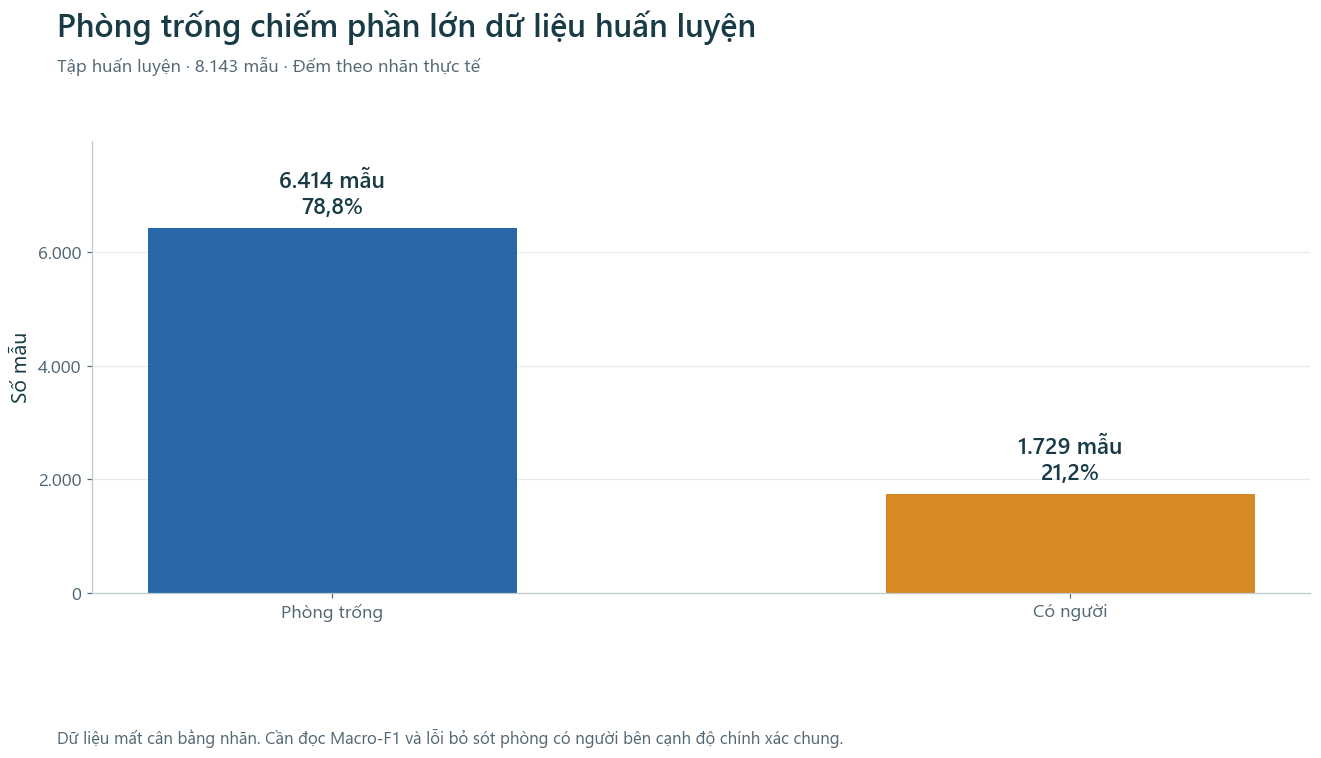

Nhận xét: 6.414 mẫu phòng trống và 1.729 mẫu có người; nhãn mất cân bằng.


In [5]:
# Bước 05
counts_05 = class_counts.reindex([0, 1]).to_numpy()
percentages_05 = counts_05 / counts_05.sum() * 100
fig = charts.class_distribution(counts_05)
save_figure("01_occupancy_distribution.png", "01 · Phân bố trạng thái phòng",
            f"Phòng trống chiếm {charts.percent(counts_05[0]/counts_05.sum())}; đọc thêm Macro-F1 và lỗi bỏ sót có người.", fig)
plt.show(); plt.close(fig)
print(f"Nhận xét: {charts.number(counts_05[0])} mẫu phòng trống và {charts.number(counts_05[1])} mẫu có người; nhãn mất cân bằng.")


Phân bố ánh sáng và CO₂ theo trạng thái phòng

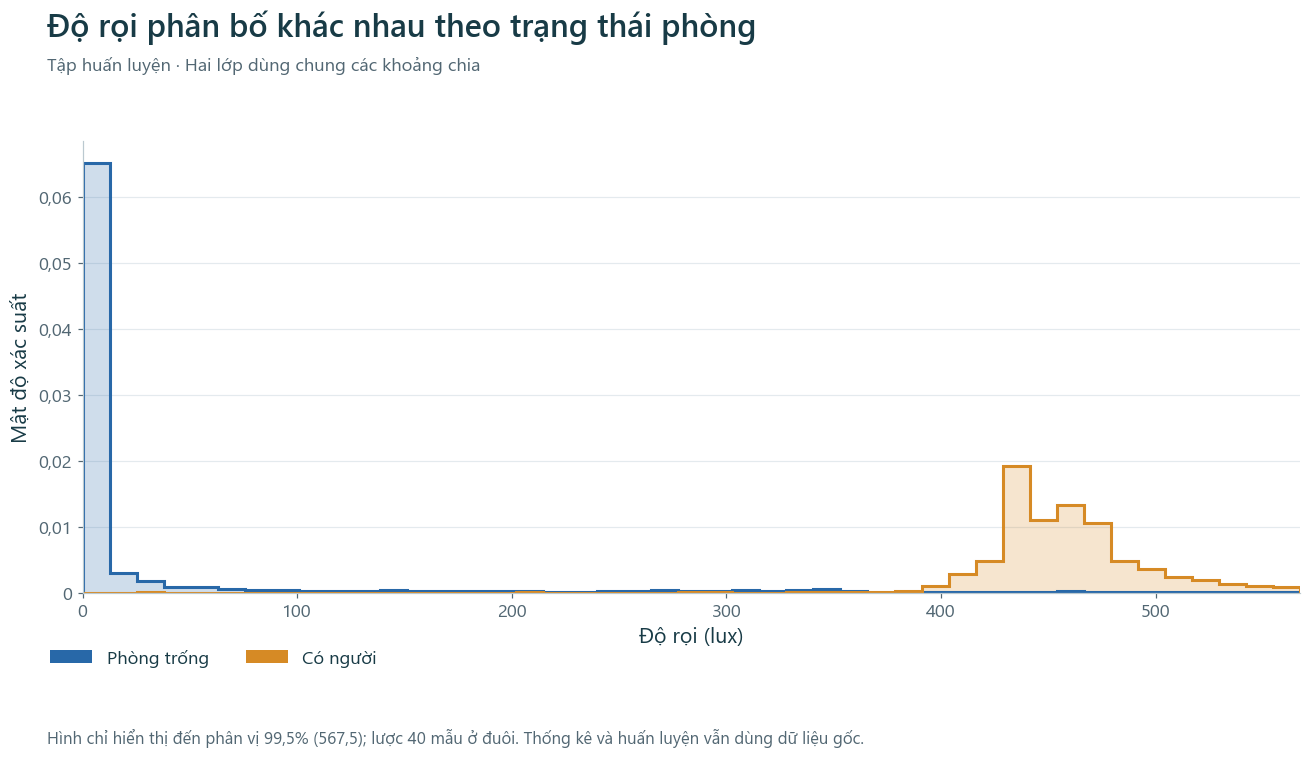

Nhận xét — Độ rọi (lux): trung vị phòng trống 0,00; có người 454,00. Đây là quan sát trên dữ liệu gốc.


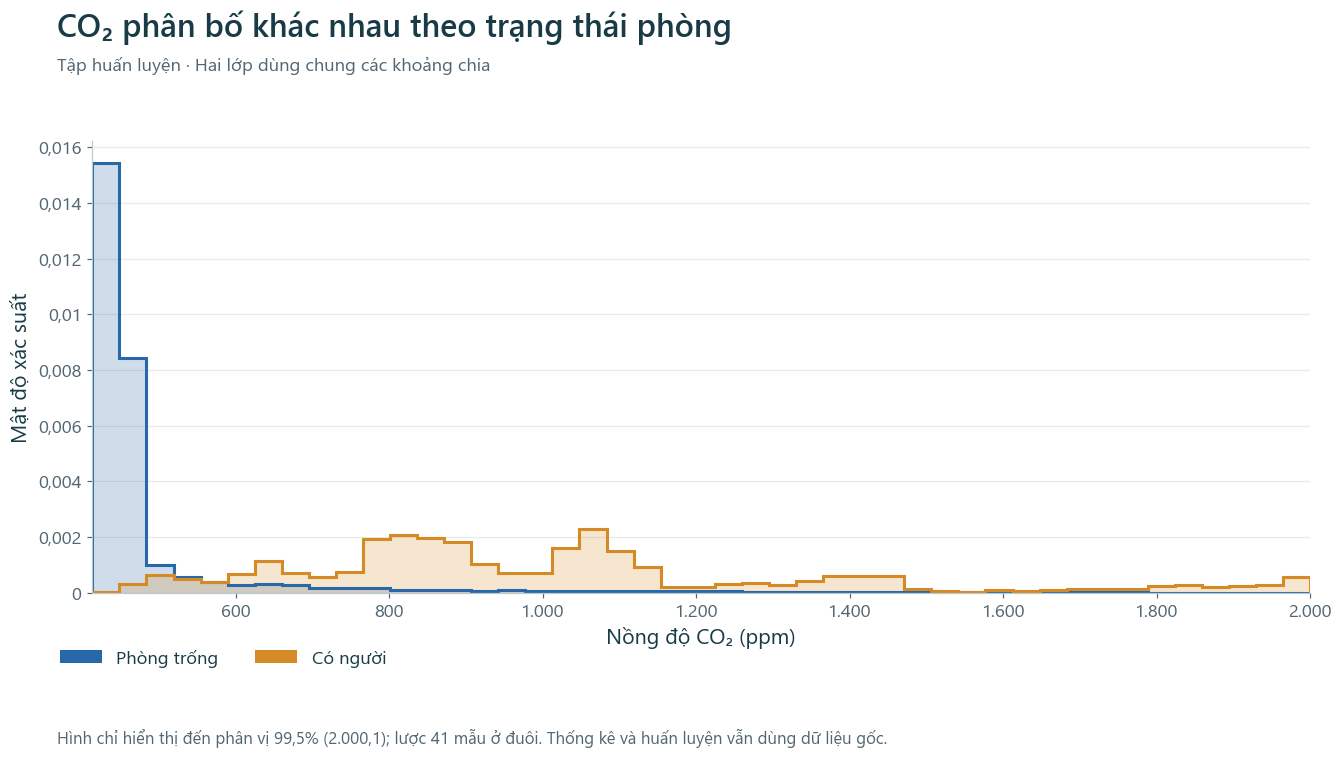

Nhận xét — Nồng độ CO₂ (ppm): trung vị phòng trống 446,00; có người 944,00. Đây là quan sát trên dữ liệu gốc.
Thống kê độ rọi và CO₂ trên dữ liệu gốc:


Light                              CO2                      
                mean     median       std        mean     median        std
Occupancy                                                                  
0          27.776000   0.000000 89.599000  490.320000 446.000000 152.920000
1         459.854000 454.000000 42.287000 1037.705000 944.000000 377.603000

In [6]:
# Bước 06
sensor_info_06 = [("Light", "02_light_distribution.png"), ("CO2", "03_co2_distribution.png")]
for feature, filename in sensor_info_06:
    fig = charts.signal_distribution(train_df, feature)
    title = "02 · Phân bố độ rọi" if feature == "Light" else "03 · Phân bố nồng độ CO₂"
    save_figure(filename, title, "Hai lớp dùng chung biên histogram; hình giới hạn đến phân vị 99,5%, mô hình dùng dữ liệu gốc.", fig)
    plt.show(); plt.close(fig)
    medians = train_df.groupby(TARGET)[feature].median()
    print(f"Nhận xét — {charts.FEATURE_LABELS[feature]}: trung vị phòng trống {charts.number(medians.loc[0], 2)}; có người {charts.number(medians.loc[1], 2)}. Đây là quan sát trên dữ liệu gốc.")
sensor_stats_06 = train_df.groupby(TARGET)[["Light", "CO2"]].agg(["mean", "median", "std"])
print("Thống kê độ rọi và CO₂ trên dữ liệu gốc:")
display(sensor_stats_06.round(3))


Quan hệ giữa nhiệt độ và độ ẩm

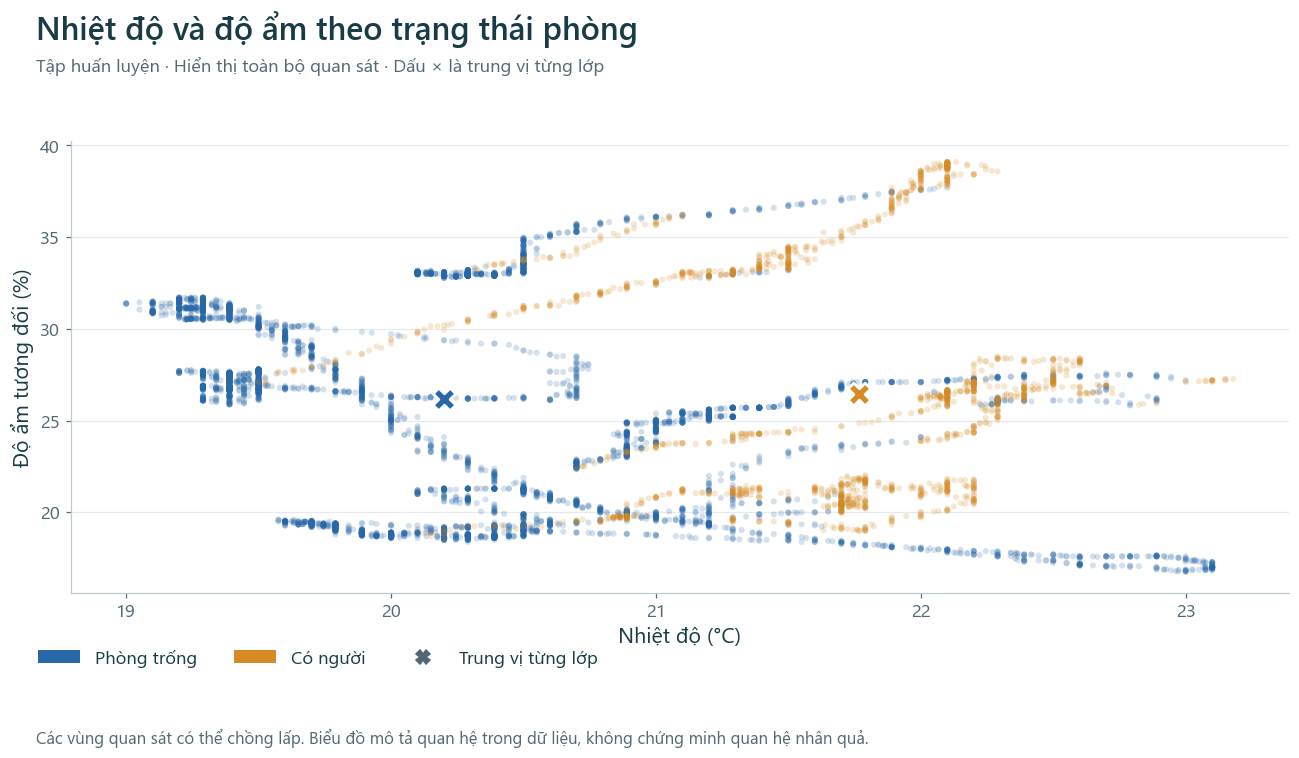

,Temperature,Humidity
Occupancy,,
0,20.200000,26.188000
1,21.768000,26.442000


Nhận xét: đối chiếu các trung vị và vùng chồng lấp; không kết luận nguyên nhân từ đồ thị phân tán.


In [7]:
# Bước 07
fig = charts.temperature_humidity(train_df)
save_figure("04_temperature_humidity.png", "04 · Nhiệt độ và độ ẩm",
            "Toàn bộ quan sát được giữ; dấu × thể hiện trung vị từng lớp, không phải ranh giới quyết định.", fig)
plt.show(); plt.close(fig)
temp_humidity_stats_07 = train_df.groupby(TARGET)[["Temperature", "Humidity"]].median()
display(temp_humidity_stats_07.round(3))
print("Nhận xét: đối chiếu các trung vị và vùng chồng lấp; không kết luận nguyên nhân từ đồ thị phân tán.")


Tương quan giữa năm cảm biến

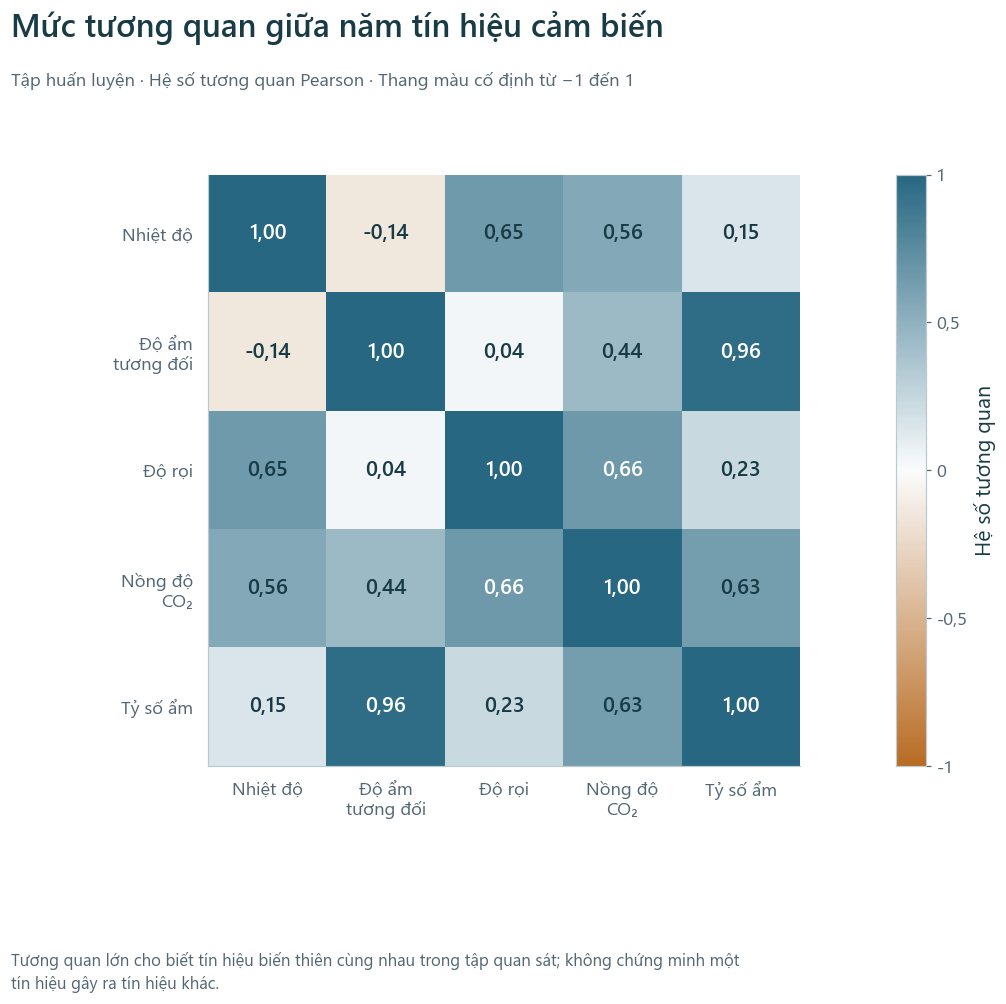

,Temperature,Humidity,Light,CO2,HumidityRatio
Temperature,1.000000,-0.142000,0.650000,0.560000,0.152000
Humidity,-0.142000,1.000000,0.038000,0.439000,0.955000
Light,0.650000,0.038000,1.000000,0.664000,0.230000
CO2,0.560000,0.439000,0.664000,1.000000,0.627000
HumidityRatio,0.152000,0.955000,0.230000,0.627000,1.000000


Nhận xét: cặp có |tương quan| lớn nhất là Độ ẩm tương đối (%) và Tỷ số ẩm (kg/kg), r = 0,955. Không chứng minh nhân quả.


In [8]:
# Bước 08
corr_matrix_08 = train_df[FEATURES].corr(method="pearson")
fig = charts.correlation(corr_matrix_08)
save_figure("05_sensor_correlation.png", "05 · Tương quan cảm biến",
            "Mối liên hệ giữa tín hiệu, với thang màu cố định −1 đến 1; không suy diễn nhân quả.", fig)
plt.show(); plt.close(fig)
display(corr_matrix_08.round(3))
off_diagonal = corr_matrix_08.where(~np.eye(len(FEATURES), dtype=bool)).abs().stack()
pair = off_diagonal.idxmax()
print(f"Nhận xét: cặp có |tương quan| lớn nhất là {charts.FEATURE_LABELS[pair[0]]} và {charts.FEATURE_LABELS[pair[1]]}, r = {charts.number(corr_matrix_08.loc[pair[0],pair[1]], 3)}. Không chứng minh nhân quả.")


Diễn biến cảm biến theo thời gian

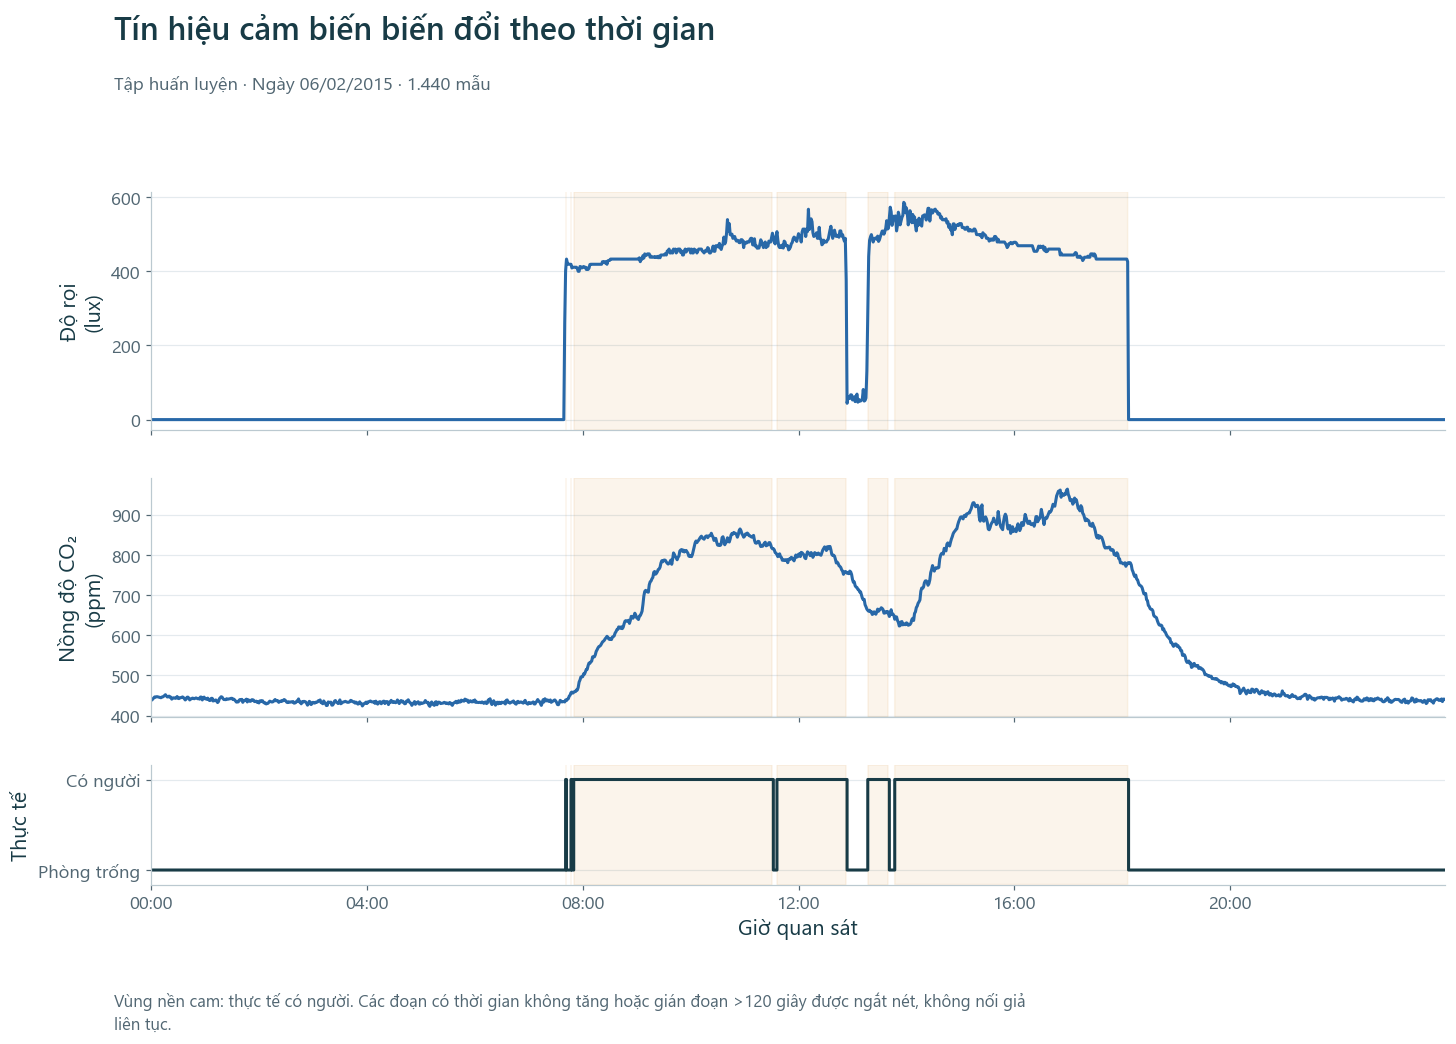

Nhận xét: ngày được chọn có 586 mẫu có người/1440 mẫu. Tín hiệu và nhãn thay đổi theo thời gian, cần đánh giá theo các khối thời gian tách biệt.


In [9]:
# Bước 09
selected_day_09 = daily_distribution.loc[daily_distribution["occupied_samples"].idxmax(), "day"]
day_data_09 = train_df.loc[train_df["date"].dt.date == selected_day_09].sort_values("date").reset_index(drop=True)
fig = charts.temporal_signals(day_data_09, selected_day_09)
save_figure("06_temporal_sensor_patterns.png", "06 · Tín hiệu theo thời gian",
            f"Ngày {pd.Timestamp(selected_day_09):%d/%m/%Y}: theo dõi độ rọi, CO₂ và nhãn thực tế trên cùng trục thời gian.", fig)
plt.show(); plt.close(fig)
print(f"Nhận xét: ngày được chọn có {int(day_data_09.Occupancy.sum())} mẫu có người/{len(day_data_09)} mẫu. Tín hiệu và nhãn thay đổi theo thời gian, cần đánh giá theo các khối thời gian tách biệt.")


Dữ liệu cảm biến có sự mất cân bằng giữa hai trạng thái phòng. Ánh sáng và CO₂ thể hiện khả năng phân biệt rõ rệt, trong khi nhiệt độ và độ ẩm cung cấp thông tin bổ trợ. Các tín hiệu thay đổi theo thời gian với tốc độ khác nhau, cho thấy cần đánh giá mô hình trên những giai đoạn thời gian tách biệt và đặc biệt quan tâm đến lỗi nhận nhầm phòng có người thành phòng trống.

In [10]:
# Bước 10
eda_observations = pd.DataFrame({
    "Đặc trưng": FEATURES,
    "Trung vị phòng trống": train_df.loc[train_df[TARGET] == 0, FEATURES].median().to_numpy(),
    "Trung vị có người": train_df.loc[train_df[TARGET] == 1, FEATURES].median().to_numpy(),
})
display(eda_observations)
print(f"Tập train: {len(train_df):,} mẫu; có người {y_train.mean():.2%}; phòng trống {1-y_train.mean():.2%}.")
print("Tương quan và phân bố khác nhau là bằng chứng mô tả, không chứng minh quan hệ nhân quả.")
print("Các khối thời gian lân cận vẫn có thể tương quan; grouped CV không bảo đảm độc lập hoàn toàn.")


,Đặc trưng,Trung vị phòng trống,Trung vị có người
0,Temperature,20.200000,21.767500
1,Humidity,26.187500,26.442500
2,Light,0.000000,454.000000
3,CO2,446.000000,944.000000
4,HumidityRatio,0.003779,0.004347


Tập train: 8,143 mẫu; có người 21.23%; phòng trống 78.77%.
Tương quan và phân bố khác nhau là bằng chứng mô tả, không chứng minh quan hệ nhân quả.
Các khối thời gian lân cận vẫn có thể tương quan; grouped CV không bảo đảm độc lập hoàn toàn.


## B. Baseline Logistic BTC — Đối chứng và thiết kế đánh giá

Pipeline theo `AI04/train.py`: **median imputation → StandardScaler → LogisticRegression(C=1, class_weight=None, max_iter=1000, random_state=2026)**. Tất cả bước tiền xử lý được fit bên trong train của từng fold.

Nạp baseline ứng dụng và fit lại một bản trong bộ nhớ trên `datatraining.txt` để đối chiếu. Không ghi đè baseline. Các kết quả CV baseline sẽ được lấy từ chính lượt search Logistic ở phần C, dùng cùng fold và không huấn luyện lặp lại riêng.

**Macro-F1** là trung bình F1 của hai lớp. **Recall(có người) = TP/(TP+FN)**. **False Empty Rate = FN/(FN+TP)**, với lớp dương là có người. Luôn báo cáo cả số FN vì một tỷ lệ nhỏ có thể chỉ đến từ ít trường hợp.

In [11]:
# Bước 11
# 1. Duong dan baseline da huan luyen
btc_model_path = BTC_OUTPUT_DIR / "model.joblib"
btc_metrics_path = BTC_OUTPUT_DIR / "metrics.json"

if not btc_model_path.is_file():
    raise FileNotFoundError(
        f"Khong tim thay BTC model: {btc_model_path}\n"
        "Hay chay AI04/train.py theo huong dan BTC truoc."
    )

# 2. Nap mo hinh BTC
btc_model = joblib.load(btc_model_path)

# 3. Dinh nghia cau hinh BTC de su dung trong CV
# Model nay chua fit. Moi fold se duoc fit rieng.
btc_lr_template = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=SEED
    )
)

# 4. Kiem tra mo hinh da nap
expected_steps = [
    "simpleimputer",
    "standardscaler",
    "logisticregression"
]

actual_steps = list(btc_model.named_steps.keys())

assert actual_steps == expected_steps, (
    f"Pipeline BTC khong dung nhu mong doi: {actual_steps}"
)

assert list(btc_model.classes_) == [0, 1], (
    "Nhan cua mo hinh BTC khong phai [0, 1]."
)

# 5. In cau hinh Logistic Regression
btc_classifier = btc_model.named_steps["logisticregression"]

print("=" * 65)
print("BTC LOGISTIC REGRESSION")
print("=" * 65)

print("Model path:", btc_model_path)
print("Pipeline :", " -> ".join(actual_steps))
print("Max iterations:", btc_classifier.max_iter)
print("C:", btc_classifier.C)
print("Class weight:", btc_classifier.class_weight)
print("Random state:", btc_classifier.random_state)


# Chứng cứ tái lập baseline: chỉ fit trên train, không dùng nhãn validation.
btc_reproduced = clone(btc_lr_template)
btc_reproduced.fit(X_train, y_train)
np.testing.assert_allclose(btc_model.predict_proba(X_train), btc_reproduced.predict_proba(X_train), rtol=1e-10, atol=1e-12)
assert list(btc_model.feature_names_in_) == FEATURES
baseline_provenance = {
    "source": "AI04/train.py", "train_file": "data/AI04/datatraining.txt",
    "train_sha256": sha256_file(TRAIN_PATH), "training_samples": len(X_train),
    "feature_order": FEATURES, "artifact_sha256": sha256_file(btc_model_path),
    "reproduced_training_probabilities_match": True,
    "limitation": "Prediction agreement corroborates reproducibility, not an independent audit of historical training provenance.",
}
print("Baseline fit lại trong bộ nhớ khớp xác suất artifact trên toàn bộ train.")


BTC LOGISTIC REGRESSION
Model path: C:\nam4\Nam4\olypic\vong3\UNETI15\outputs\AI04\model.joblib
Pipeline : simpleimputer -> standardscaler -> logisticregression
Max iterations: 1000
C: 1.0
Class weight: None
Random state: 2026
Baseline fit lại trong bộ nhớ khớp xác suất artifact trên toàn bộ train.


Tạo Cross-Validation theo nhóm 2 giờ

In [12]:
# Bước 12
# Group unit: 2-hour time blocks

# 1. Tao nhom 2 gio
time_groups_2h = train_df["date"].dt.floor("2h")

print("=" * 65)
print("GROUPED CROSS-VALIDATION")
print("=" * 65)

print("Total records:", len(train_df))
print("Unique 2-hour blocks:", time_groups_2h.nunique())

# 2. Khoi tao bo chia
cv_grouped = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

# 3. Tao fold mot lan
# Se tai su dung cho tat ca model
grouped_splits = list(
    cv_grouped.split(
        X_train,
        y_train,
        groups=time_groups_2h
    )
)

# 4. Kiem tra tung fold
grouped_fold_records = []

for fold_id, (train_idx, valid_idx) in enumerate(
    grouped_splits, start=1
):

    train_groups = set(
        time_groups_2h.iloc[train_idx]
    )

    valid_groups = set(
        time_groups_2h.iloc[valid_idx]
    )

    # Khong duoc trung nhom 2 gio
    overlap = train_groups.intersection(valid_groups)

    assert len(overlap) == 0, (
        f"Fold {fold_id} bi trung nhom thoi gian."
    )

    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    # Dem nhom validation lien ke nhom training
    adjacent_count = 0

    for block in valid_groups:
        previous_block = block - pd.Timedelta(hours=2)
        next_block = block + pd.Timedelta(hours=2)

        if (
            previous_block in train_groups
            or next_block in train_groups
        ):
            adjacent_count += 1

    grouped_fold_records.append({
        "fold": fold_id,
        "train_samples": len(train_idx),
        "valid_samples": len(valid_idx),
        "train_occupied": int(y_fold_train.sum()),
        "valid_occupied": int(y_fold_valid.sum()),
        "train_occupied_ratio": float(y_fold_train.mean()),
        "valid_occupied_ratio": float(y_fold_valid.mean()),
        "train_groups": len(train_groups),
        "valid_groups": len(valid_groups),
        "adjacent_valid_groups": adjacent_count,
        "overlapping_groups": len(overlap)
    })

# 5. Bang thong ke fold
grouped_fold_df = pd.DataFrame(grouped_fold_records)

display(grouped_fold_df.round(4))

# 6. Canh bao neu fold khong du hai lop
for row in grouped_fold_records:

    occupied = row["valid_occupied"]
    empty = row["valid_samples"] - occupied

    if occupied == 0 or empty == 0:
        print(
            f"WARNING: Fold {row['fold']} "
            "khong co du hai lop!"
        )

# 7. Luu cau truc fold

print("\nIMPORTANT:")
print(
    "Khong trung nhom 2 gio, nhung cac nhom "
    "lien ke van co the tuong quan."
)


GROUPED CROSS-VALIDATION
Total records: 8143
Unique 2-hour blocks: 69


,fold,train_samples,valid_samples,train_occupied,valid_occupied,train_occupied_ratio,valid_occupied_ratio,train_groups,valid_groups,adjacent_valid_groups,overlapping_groups
0,1,5387,2756,1110,619,0.206100,0.224600,46,23,23,0
1,2,5369,2774,1084,645,0.201900,0.232500,45,24,20,0
2,3,5530,2613,1264,465,0.228600,0.178000,47,22,21,0



IMPORTANT:
Khong trung nhom 2 gio, nhung cac nhom lien ke van co the tuong quan.


Cross-Validation kiểm tra khả năng tổng quát hóa theo thời gian

In [13]:
# Bước 13
#
# Train: Only earlier observations
# Validation: One later observation day
# Temporal gap: At least 2 hours

print("=" * 65)
print("TEMPORAL ROBUSTNESS VALIDATION")
print("=" * 65)

# 1. Danh sach ngay thu thap trong training
observation_days = sorted(
    train_df["date"].dt.normalize().unique()
)

# 2. Quy dinh muc toi thieu de fold co y nghia
MIN_TRAIN_OCCUPIED = 100
MIN_VALID_OCCUPIED = 20
MIN_VALID_EMPTY = 20
TEMPORAL_GAP_HOURS = 2

# 3. Tao cac lan kiem tra theo thoi gian
temporal_splits = []
temporal_fold_records = []

for observation_day in observation_days:

    day_mask = (
        train_df["date"].dt.normalize() == observation_day
    )

    valid_idx = np.flatnonzero(
        day_mask.to_numpy()
    )

    if len(valid_idx) == 0:
        continue

    valid_start = train_df.loc[
        day_mask, "date"
    ].min()

    cutoff_time = (
        valid_start -
        pd.Timedelta(hours=TEMPORAL_GAP_HOURS)
    )

    # Chi cho phep huan luyen tren du lieu truoc cutoff
    earlier_mask = train_df["date"] < cutoff_time

    train_idx = np.flatnonzero(
        earlier_mask.to_numpy()
    )

    if len(train_idx) == 0:
        continue

    y_earlier = y_train.iloc[train_idx]
    y_later = y_train.iloc[valid_idx]

    train_occupied = int(y_earlier.sum())
    valid_occupied = int(y_later.sum())
    valid_empty = len(valid_idx) - valid_occupied

    # Bo qua nhung fold khong du du lieu hai lop
    if train_occupied < MIN_TRAIN_OCCUPIED:
        continue

    if valid_occupied < MIN_VALID_OCCUPIED:
        continue

    if valid_empty < MIN_VALID_EMPTY:
        continue

    # Xac minh train thuc su nam truoc validation
    train_end = train_df["date"].iloc[train_idx].max()
    valid_begin = train_df["date"].iloc[valid_idx].min()

    actual_gap_hours = (
        valid_begin - train_end
    ).total_seconds() / 3600

    assert actual_gap_hours >= TEMPORAL_GAP_HOURS
    assert set(train_idx).isdisjoint(set(valid_idx))

    fold_id = len(temporal_splits) + 1

    temporal_splits.append(
        (train_idx, valid_idx)
    )

    temporal_fold_records.append({
        "fold": fold_id,
        "valid_day": str(pd.Timestamp(observation_day).date()),
        "train_samples": len(train_idx),
        "valid_samples": len(valid_idx),
        "train_occupied": train_occupied,
        "valid_occupied": valid_occupied,
        "valid_empty": valid_empty,
        "valid_occupied_ratio": float(y_later.mean()),
        "gap_hours": actual_gap_hours
    })

# 4. Kiem tra ket qua
temporal_fold_df = pd.DataFrame(
    temporal_fold_records
)

if len(temporal_splits) < 2:
    raise ValueError(
        "Khong tao duoc du fold thoi gian hop le. "
        "Can xem lai dieu kien va cau truc du lieu."
    )

print("Temporal folds:", len(temporal_splits))

display(temporal_fold_df.round(4))

# 5. Luu bang thong ke

print("\nIMPORTANT:")
print("Moi fold chi train tren du lieu truoc ngay danh gia.")
print("Khong su dung datatest.txt hoac datatest2.txt.")
print(
    "Day la phep danh gia do ben vung; "
    "khong phai CV ngan chan moi loai temporal leakage."
)


TEMPORAL ROBUSTNESS VALIDATION
Temporal folds: 3


,fold,valid_day,train_samples,valid_samples,train_occupied,valid_occupied,valid_empty,valid_occupied_ratio,gap_hours
0,1,2015-02-06,1689,1440,555,586,854,0.406900,2.016700
1,2,2015-02-09,6009,1440,1141,534,906,0.370800,2.016700
2,3,2015-02-10,7449,574,1675,54,520,0.094100,2.016700



IMPORTANT:
Moi fold chi train tren du lieu truoc ngay danh gia.
Khong su dung datatest.txt hoac datatest2.txt.
Day la phep danh gia do ben vung; khong phai CV ngan chan moi loai temporal leakage.


In [14]:
# Bước 14
# 2. Ham tinh cac chi so phan loai
def calculate_classification_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    occupied_total = fn + tp

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_empty": f1_score(
            y_true, y_pred,
            pos_label=0,
            zero_division=0
        ),
        "f1_occupied": f1_score(
            y_true, y_pred,
            pos_label=1,
            zero_division=0
        ),
        "recall_occupied": recall_score(
            y_true, y_pred,
            pos_label=1,
            zero_division=0
        ),
        "false_empty_rate": (
            fn / occupied_total
            if occupied_total > 0 else np.nan
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


# 3. Ham chay cac mo hinh tren cung bo fold
def evaluate_models_cv(
    templates,
    splits,
    X,
    y,
    protocol_name
):

    fold_records = []
    summary_records = []

    all_oof_probabilities = {}
    all_oof_predictions = {}
    all_oof_fold_ids = {}

    for model_name, template in templates.items():

        print(f"\nEvaluating: {model_name}")

        oof_predictions = np.full(
            len(y), -1, dtype=int
        )

        oof_probabilities = np.full(
            len(y), np.nan, dtype=float
        )

        oof_fold_ids = np.full(
            len(y), -1, dtype=int
        )

        fold_f1_scores = []
        total_fit_seconds = 0.0

        for fold_id, (train_idx, valid_idx) in enumerate(
            splits, start=1
        ):

            model = clone(template)

            X_fold_train = X.iloc[train_idx]
            X_fold_valid = X.iloc[valid_idx]

            y_fold_train = y.iloc[train_idx]
            y_fold_valid = y.iloc[valid_idx]

            # Dam bao khong du doan lap lai cung mot mau
            assert np.all(
                oof_fold_ids[valid_idx] == -1
            ), "Validation indices bi trung giua cac fold."

            # Huan luyen chi tren train cua fold
            start_time = time.perf_counter()

            model.fit(
                X_fold_train,
                y_fold_train
            )

            fit_seconds = (
                time.perf_counter() - start_time
            )

            total_fit_seconds += fit_seconds

            # Du doan tren validation cua fold
            predictions = model.predict(
                X_fold_valid
            )

            occupied_index = list(
                model.classes_
            ).index(1)

            probabilities = model.predict_proba(
                X_fold_valid
            )[:, occupied_index]

            # Luu du doan OOF
            oof_predictions[valid_idx] = predictions
            oof_probabilities[valid_idx] = probabilities
            oof_fold_ids[valid_idx] = fold_id

            # Tinh chi so cua fold
            fold_metrics = calculate_classification_metrics(
                y_fold_valid,
                predictions
            )

            fold_f1_scores.append(
                fold_metrics["macro_f1"]
            )

            fold_records.append({
                "protocol": protocol_name,
                "model": model_name,
                "fold": fold_id,
                "train_samples": len(train_idx),
                "valid_samples": len(valid_idx),
                "fit_seconds": fit_seconds,
                **fold_metrics
            })

            print(
                f"  Fold {fold_id}: "
                f"Macro-F1={fold_metrics['macro_f1']:.6f} | "
                f"FER={fold_metrics['false_empty_rate']:.6f} | "
                f"FN={fold_metrics['FN']}"
            )

        # Chi danh gia cac mau da co du doan OOF
        evaluated_mask = oof_fold_ids > 0

        assert np.isfinite(
            oof_probabilities[evaluated_mask]
        ).all()

        pooled_metrics = calculate_classification_metrics(
            y.iloc[np.flatnonzero(evaluated_mask)],
            oof_predictions[evaluated_mask]
        )

        summary_records.append({
            "protocol": protocol_name,
            "model": model_name,
            "evaluated_samples": int(evaluated_mask.sum()),
            "total_samples": len(y),
            "coverage": float(evaluated_mask.mean()),
            "fold_count": len(splits),
            "mean_fold_macro_f1": float(
                np.mean(fold_f1_scores)
            ),
            "std_fold_macro_f1": float(
                np.std(fold_f1_scores, ddof=1)
                if len(fold_f1_scores) > 1 else 0
            ),
            "fit_seconds": total_fit_seconds,
            **pooled_metrics
        })

        all_oof_probabilities[model_name] = (
            oof_probabilities
        )

        all_oof_predictions[model_name] = (
            oof_predictions
        )

        all_oof_fold_ids[model_name] = (
            oof_fold_ids
        )

    fold_df = pd.DataFrame(fold_records)
    summary_df = pd.DataFrame(summary_records)

    return (
        fold_df,
        summary_df,
        all_oof_probabilities,
        all_oof_predictions,
        all_oof_fold_ids
    )


## C. Cải tiến Logistic — Search, lựa chọn và ablation

Ba thành phần nghiên cứu: **đa thức bậc 2** bổ sung tương tác/phi tuyến; **class_weight=balanced** điều chỉnh trọng số hai lớp; **C** điều chỉnh mức regularization. Các thành phần có thể tạo sự đánh đổi giữa Macro-F1 và False Empty Rate.

Giữ 16 cấu hình gốc: bật/tắt đa thức × C ∈ {0.03, 0.3, 1, 3} × trọng số {None, balanced}. Trong tên cũ, **poly=1 là bật PolynomialFeatures(degree=2)**; giữ tên gốc để truy vết.

Lọc cấu hình không kém baseline về F1 và FER ở cả hai protocol; xếp hạng theo **temporal F1 giảm dần → temporal FER tăng dần → grouped F1 giảm dần**. Quy tắc này không chọn FER thấp nhất bằng mọi giá. CV đã dùng để chọn mô hình là bằng chứng phát triển nội bộ, không phải đánh giá độc lập sau lựa chọn.

Khai báo các cấu hình Logistic Regression

In [15]:
# Bước 15
C_VALUES = [0.03, 0.3, 1.0, 3.0]
WEIGHT_OPTIONS = [None, "balanced"]
POLYNOMIAL_OPTIONS = [False, True]

lr_candidates = {}

for use_poly in POLYNOMIAL_OPTIONS:
    for c_value in C_VALUES:
        for class_weight in WEIGHT_OPTIONS:

            # Dung dung cau hinh BTC lam doi chung
            if (
                not use_poly
                and c_value == 1.0
                and class_weight is None
            ):
                model_name = "BTC Logistic Regression"
                lr_candidates[model_name] = btc_lr_template
                continue

            steps = [
                SimpleImputer(strategy="median")
            ]

            if use_poly:
                steps.append(
                    PolynomialFeatures(
                        degree=2,
                        include_bias=False
                    )
                )

            steps.extend([
                StandardScaler(),
                LogisticRegression(
                    C=c_value,
                    class_weight=class_weight,
                    max_iter=1500,
                    solver="lbfgs",
                    random_state=SEED
                )
            ])

            weight_name = (
                "balanced"
                if class_weight == "balanced"
                else "none"
            )

            model_name = (
                f"LR | poly={int(use_poly)}"
                f" | C={c_value:g}"
                f" | cw={weight_name}"
            )

            lr_candidates[model_name] = make_pipeline(*steps)

assert len(lr_candidates) == 16

print("=" * 65)
print("LOGISTIC REGRESSION CONFIGURATIONS")
print("=" * 65)

for i, name in enumerate(lr_candidates, start=1):
    print(f"{i:02d}. {name}")

print("\nTotal configurations:", len(lr_candidates))


LOGISTIC REGRESSION CONFIGURATIONS
01. LR | poly=0 | C=0.03 | cw=none
02. LR | poly=0 | C=0.03 | cw=balanced
03. LR | poly=0 | C=0.3 | cw=none
04. LR | poly=0 | C=0.3 | cw=balanced
05. BTC Logistic Regression
06. LR | poly=0 | C=1 | cw=balanced
07. LR | poly=0 | C=3 | cw=none
08. LR | poly=0 | C=3 | cw=balanced
09. LR | poly=1 | C=0.03 | cw=none
10. LR | poly=1 | C=0.03 | cw=balanced
11. LR | poly=1 | C=0.3 | cw=none
12. LR | poly=1 | C=0.3 | cw=balanced
13. LR | poly=1 | C=1 | cw=none
14. LR | poly=1 | C=1 | cw=balanced
15. LR | poly=1 | C=3 | cw=none
16. LR | poly=1 | C=3 | cw=balanced

Total configurations: 16


Đánh giá tất cả cấu hình bằng hai phương pháp CV

In [16]:
# Bước 16
print("=" * 65)
print("LOGISTIC REGRESSION OPTIMIZATION")
print("=" * 65)

# 1. Danh gia tren grouped CV 2 gio
(
    lr_grouped_folds,
    lr_grouped_summary,
    lr_grouped_probabilities,
    lr_grouped_predictions,
    lr_grouped_fold_ids
) = evaluate_models_cv(
    templates=lr_candidates,
    splits=grouped_splits,
    X=X_train,
    y=y_train,
    protocol_name="LR Search - Grouped 2-hour CV"
)

# 2. Danh gia tren chronological robustness CV
(
    lr_temporal_folds,
    lr_temporal_summary,
    lr_temporal_probabilities,
    lr_temporal_predictions,
    lr_temporal_fold_ids
) = evaluate_models_cv(
    templates=lr_candidates,
    splits=temporal_splits,
    X=X_train,
    y=y_train,
    protocol_name="LR Search - Chronological"
)

# 3. Luu day du ket qua




print("\nGROUPED CV - TOP CONFIGURATIONS")
display(
    lr_grouped_summary.sort_values(
        "macro_f1", ascending=False
    )[
        ["model", "macro_f1", "false_empty_rate", "FN", "FP"]
    ].head(10).round(6)
)

print("\nTEMPORAL CV - TOP CONFIGURATIONS")
display(
    lr_temporal_summary.sort_values(
        "macro_f1", ascending=False
    )[
        ["model", "macro_f1", "false_empty_rate", "FN", "FP"]
    ].head(10).round(6)
)


LOGISTIC REGRESSION OPTIMIZATION

Evaluating: LR | poly=0 | C=0.03 | cw=none
  Fold 1: Macro-F1=0.986640 | FER=0.001616 | FN=1


  Fold 2: Macro-F1=0.957435 | FER=0.003101 | FN=2
  Fold 3: Macro-F1=0.953931 | FER=0.133333 | FN=62



Evaluating: LR | poly=0 | C=0.03 | cw=balanced
  Fold 1: Macro-F1=0.987161 | FER=0.000000 | FN=0


  Fold 2: Macro-F1=0.946047 | FER=0.001550 | FN=1


  Fold 3: Macro-F1=0.950760 | FER=0.004301 | FN=2


Evaluating: LR | poly=0 | C=0.3 | cw=none
  Fold 1: Macro-F1=0.986640 | FER=0.001616 | FN=1
  Fold 2: Macro-F1=0.956973 | FER=0.003101 | FN=2


... (35 outputs left out)

  Fold 3: Macro-F1=0.989946 | FER=0.000000 | FN=0

GROUPED CV - TOP CONFIGURATIONS


,model,macro_f1,false_empty_rate,FN,FP
9,LR | poly=1 | C=0.03 | cw=balanced,0.978125,0.002313,4,118
10,LR | poly=1 | C=0.3 | cw=none,0.971684,0.038172,66,89
12,LR | poly=1 | C=1 | cw=none,0.971283,0.040486,70,87
11,LR | poly=1 | C=0.3 | cw=balanced,0.969904,0.022556,39,128
14,LR | poly=1 | C=3 | cw=none,0.968813,0.040486,70,101
3,LR | poly=0 | C=0.3 | cw=balanced,0.968270,0.017929,31,146
13,LR | poly=1 | C=1 | cw=balanced,0.968050,0.027762,48,129
0,LR | poly=0 | C=0.03 | cw=none,0.967126,0.037594,65,116
8,LR | poly=1 | C=0.03 | cw=none,0.967082,0.046848,81,99
5,LR | poly=0 | C=1 | cw=balanced,0.966768,0.023135,40,145



TEMPORAL CV - TOP CONFIGURATIONS


,model,macro_f1,false_empty_rate,FN,FP
11,LR | poly=1 | C=0.3 | cw=balanced,0.991970,0.001704,2,23
9,LR | poly=1 | C=0.03 | cw=balanced,0.989094,0.002555,3,31
8,LR | poly=1 | C=0.03 | cw=none,0.986782,0.016184,19,22
7,LR | poly=0 | C=3 | cw=balanced,0.979915,0.001704,2,61
5,LR | poly=0 | C=1 | cw=balanced,0.978970,0.001704,2,64
3,LR | poly=0 | C=0.3 | cw=balanced,0.976153,0.000852,1,74
6,LR | poly=0 | C=3 | cw=none,0.974583,0.028109,33,46
4,BTC Logistic Regression,0.973950,0.028109,33,48
2,LR | poly=0 | C=0.3 | cw=none,0.973666,0.025554,30,52
0,LR | poly=0 | C=0.03 | cw=none,0.966888,0.036627,43,60


Lựa chọn cấu hình Logistic Regression

In [17]:
# Bước 17
# 1. Lay cot can thiet tu hai bang
grouped_selection = lr_grouped_summary[
    ["model", "macro_f1", "false_empty_rate", "FN"]
].rename(columns={
    "macro_f1": "grouped_f1",
    "false_empty_rate": "grouped_fer",
    "FN": "grouped_fn"
})

temporal_selection = lr_temporal_summary[
    ["model", "macro_f1", "false_empty_rate", "FN"]
].rename(columns={
    "macro_f1": "temporal_f1",
    "false_empty_rate": "temporal_fer",
    "FN": "temporal_fn"
})

# 2. Gop theo ten cau hinh
lr_selection_df = grouped_selection.merge(
    temporal_selection,
    on="model",
    how="inner",
    validate="one_to_one"
)

assert len(lr_selection_df) == len(lr_candidates)

# 3. Lay baseline
baseline_selection = lr_selection_df.loc[
    lr_selection_df["model"] == "BTC Logistic Regression"
].iloc[0]

# 4. Loc ung vien dat ca 4 dieu kien
eligible_lr = lr_selection_df.loc[
    (lr_selection_df["grouped_f1"] >= baseline_selection["grouped_f1"])
    &
    (lr_selection_df["grouped_fer"] <= baseline_selection["grouped_fer"])
    &
    (lr_selection_df["temporal_f1"] >= baseline_selection["temporal_f1"])
    &
    (lr_selection_df["temporal_fer"] <= baseline_selection["temporal_fer"])
].copy()

# 5. Xep hang ung vien
eligible_lr = eligible_lr.sort_values(
    by=["temporal_f1", "temporal_fer", "grouped_f1"],
    ascending=[False, True, False]
).reset_index(drop=True)

best_lr_name = eligible_lr.iloc[0]["model"]

print("=" * 65)
print("LOGISTIC REGRESSION SELECTION")
print("=" * 65)

print("\nBASELINE PERFORMANCE")
display(
    lr_selection_df.loc[
        lr_selection_df["model"] == "BTC Logistic Regression"
    ].round(6)
)

print("\nELIGIBLE CONFIGURATIONS")
display(eligible_lr.round(6))

print("\nSELECTED MODEL:")
print(best_lr_name)

# 6. Luu bang so sanh
lr_selection_df.to_csv(
    RESULTS_DIR / "lr_selection_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# 7. Luu quy tac va ket qua lua chon
lr_selection_metadata = {
    "selected_model": best_lr_name,
    "selection_source": "datatraining.txt only",
    "primary_metric": "temporal_macro_f1",
    "constraints": [
        "grouped_f1 >= btc_grouped_f1",
        "grouped_fer <= btc_grouped_fer",
        "temporal_f1 >= btc_temporal_f1",
        "temporal_fer <= btc_temporal_fer"
    ],
    "ranking": [
        "temporal_f1 descending",
        "temporal_fer ascending",
        "grouped_f1 descending"
    ],
    "random_seed": SEED
}



LOGISTIC REGRESSION SELECTION

BASELINE PERFORMANCE


,model,grouped_f1,grouped_fer,grouped_fn,temporal_f1,temporal_fer,temporal_fn
4,BTC Logistic Regression,0.961692,0.052053,90,0.973950,0.028109,33



ELIGIBLE CONFIGURATIONS


,model,grouped_f1,grouped_fer,grouped_fn,temporal_f1,temporal_fer,temporal_fn
0,LR | poly=1 | C=0.3 | cw=balanced,0.969904,0.022556,39,0.991970,0.001704,2
1,LR | poly=1 | C=0.03 | cw=balanced,0.978125,0.002313,4,0.989094,0.002555,3
2,LR | poly=1 | C=0.03 | cw=none,0.967082,0.046848,81,0.986782,0.016184,19
3,LR | poly=0 | C=3 | cw=balanced,0.966236,0.023713,41,0.979915,0.001704,2
4,LR | poly=0 | C=1 | cw=balanced,0.966768,0.023135,40,0.978970,0.001704,2
5,LR | poly=0 | C=0.3 | cw=balanced,0.968270,0.017929,31,0.976153,0.000852,1
6,BTC Logistic Regression,0.961692,0.052053,90,0.973950,0.028109,33



SELECTED MODEL:
LR | poly=1 | C=0.3 | cw=balanced


Ablation Study: Kiểm tra tác động của từng thành phần

In [18]:
# Bước 18
# 1. Lay cau hinh da chon tu bước trước
selected_template = lr_candidates[best_lr_name]
selected_classifier = selected_template.named_steps["logisticregression"]

selected_c = selected_classifier.C
selected_weight = selected_classifier.class_weight
selected_has_poly = (
    "polynomialfeatures" in selected_template.named_steps
)

print("=" * 65)
print("LOGISTIC REGRESSION ABLATION")
print("=" * 65)

print("Selected model:", best_lr_name)
print("C:", selected_c)
print("Class weight:", selected_weight)
print("Polynomial:", selected_has_poly)


# 2. Tim ten mo hinh theo cau hinh
def find_lr_candidate(use_poly, c_value, class_weight):

    for name, pipeline in lr_candidates.items():

        classifier = pipeline.named_steps["logisticregression"]

        has_poly = "polynomialfeatures" in pipeline.named_steps

        same_poly = has_poly == use_poly
        same_c = np.isclose(classifier.C, c_value)
        same_weight = classifier.class_weight == class_weight

        if same_poly and same_c and same_weight:
            return name

    raise ValueError(
        f"Khong tim thay cau hinh: "
        f"poly={use_poly}, C={c_value}, "
        f"class_weight={class_weight}"
    )


# 3. Tao danh sach thuc nghiem
ablation_models = {
    "BTC baseline": "BTC Logistic Regression",

    "Selected model": best_lr_name,

    "Without PolynomialFeatures": find_lr_candidate(
        use_poly=False,
        c_value=selected_c,
        class_weight=selected_weight
    ),

    "Without class weighting": find_lr_candidate(
        use_poly=selected_has_poly,
        c_value=selected_c,
        class_weight=None
    ),

    "C sensitivity: 0.03": find_lr_candidate(
        use_poly=True,
        c_value=0.03,
        class_weight="balanced"
    )
}


# 4. Lay ket qua CV da tinh
ablation_records = []

for experiment_name, model_name in ablation_models.items():

    match = lr_selection_df.loc[
        lr_selection_df["model"] == model_name
    ]

    assert len(match) == 1, (
        f"Khong tim thay ket qua cua {model_name}"
    )

    row = match.iloc[0]

    ablation_records.append({
        "experiment": experiment_name,
        "model": model_name,
        "grouped_f1": row["grouped_f1"],
        "grouped_fer": row["grouped_fer"],
        "grouped_fn": int(row["grouped_fn"]),
        "temporal_f1": row["temporal_f1"],
        "temporal_fer": row["temporal_fer"],
        "temporal_fn": int(row["temporal_fn"])
    })


# 5. Tong hop
ablation_df = pd.DataFrame(ablation_records)

print("\nABLATION RESULTS:")
display(ablation_df.round(6))


# 6. So sanh voi mo hinh duoc chon
selected_row = ablation_df.loc[
    ablation_df["experiment"] == "Selected model"
].iloc[0]

ablation_df["delta_grouped_f1"] = (
    ablation_df["grouped_f1"] -
    selected_row["grouped_f1"]
)

ablation_df["delta_temporal_f1"] = (
    ablation_df["temporal_f1"] -
    selected_row["temporal_f1"]
)

ablation_df["delta_grouped_fn"] = (
    ablation_df["grouped_fn"] -
    selected_row["grouped_fn"]
)

ablation_df["delta_temporal_fn"] = (
    ablation_df["temporal_fn"] -
    selected_row["temporal_fn"]
)

print("\nDIFFERENCES RELATIVE TO SELECTED MODEL:")
display(
    ablation_df[
        [
            "experiment",
            "delta_grouped_f1",
            "delta_grouped_fn",
            "delta_temporal_f1",
            "delta_temporal_fn"
        ]
    ].round(6)
)


# 7. Luu ket qua
ablation_df.to_csv(
    RESULTS_DIR / "lr_ablation_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

without_poly = ablation_df.loc[ablation_df["experiment"] == "Without PolynomialFeatures"].iloc[0]
print(f"Ablation trên cùng folds: bỏ đa thức đổi grouped FN {int(selected_row['grouped_fn'])} → {int(without_poly['grouped_fn'])}; temporal FN {int(selected_row['temporal_fn'])} → {int(without_poly['temporal_fn'])}.")
print(f"Temporal Macro-F1 tương ứng {selected_row['temporal_f1']:.6f} → {without_poly['temporal_f1']:.6f}.")
print("Đa thức không cải thiện mọi chỉ số; quyết định giữ đa thức tuân theo quy tắc xếp hạng đã nêu.")


LOGISTIC REGRESSION ABLATION
Selected model: LR | poly=1 | C=0.3 | cw=balanced
C: 0.3
Class weight: balanced
Polynomial: True

ABLATION RESULTS:


,experiment,model,grouped_f1,grouped_fer,grouped_fn,temporal_f1,temporal_fer,temporal_fn
0,BTC baseline,BTC Logistic Regression,0.961692,0.052053,90,0.973950,0.028109,33
1,Selected model,LR | poly=1 | C=0.3 | cw=balanced,0.969904,0.022556,39,0.991970,0.001704,2
2,Without PolynomialFeatures,LR | poly=0 | C=0.3 | cw=balanced,0.968270,0.017929,31,0.976153,0.000852,1
3,Without class weighting,LR | poly=1 | C=0.3 | cw=none,0.971684,0.038172,66,0.964584,0.078365,92
4,C sensitivity: 0.03,LR | poly=1 | C=0.03 | cw=balanced,0.978125,0.002313,4,0.989094,0.002555,3



DIFFERENCES RELATIVE TO SELECTED MODEL:


,experiment,delta_grouped_f1,delta_grouped_fn,delta_temporal_f1,delta_temporal_fn
0,BTC baseline,-0.008212,51,-0.018020,31
1,Selected model,0.000000,0,0.000000,0
2,Without PolynomialFeatures,-0.001635,-8,-0.015817,-1
3,Without class weighting,0.001780,27,-0.027385,90
4,C sensitivity: 0.03,0.008221,-35,-0.002876,1


Ablation trên cùng folds: bỏ đa thức đổi grouped FN 39 → 31; temporal FN 2 → 1.
Temporal Macro-F1 tương ứng 0.991970 → 0.976153.
Đa thức không cải thiện mọi chỉ số; quyết định giữ đa thức tuân theo quy tắc xếp hạng đã nêu.


,protocol,display_model,evaluated_samples,macro_f1,false_empty_rate,FN,FP
0,LR Search - Grouped 2-hour CV,BTC Logistic Regression,8143,0.961692,0.052053,90,120
1,LR Search - Grouped 2-hour CV,LR | polynomial_degree=2 | C=0.3 | cw=balanced,8143,0.969904,0.022556,39,128
2,LR Search - Chronological,BTC Logistic Regression,3454,0.973950,0.028109,33,48
3,LR Search - Chronological,LR | polynomial_degree=2 | C=0.3 | cw=balanced,3454,0.991970,0.001704,2,23


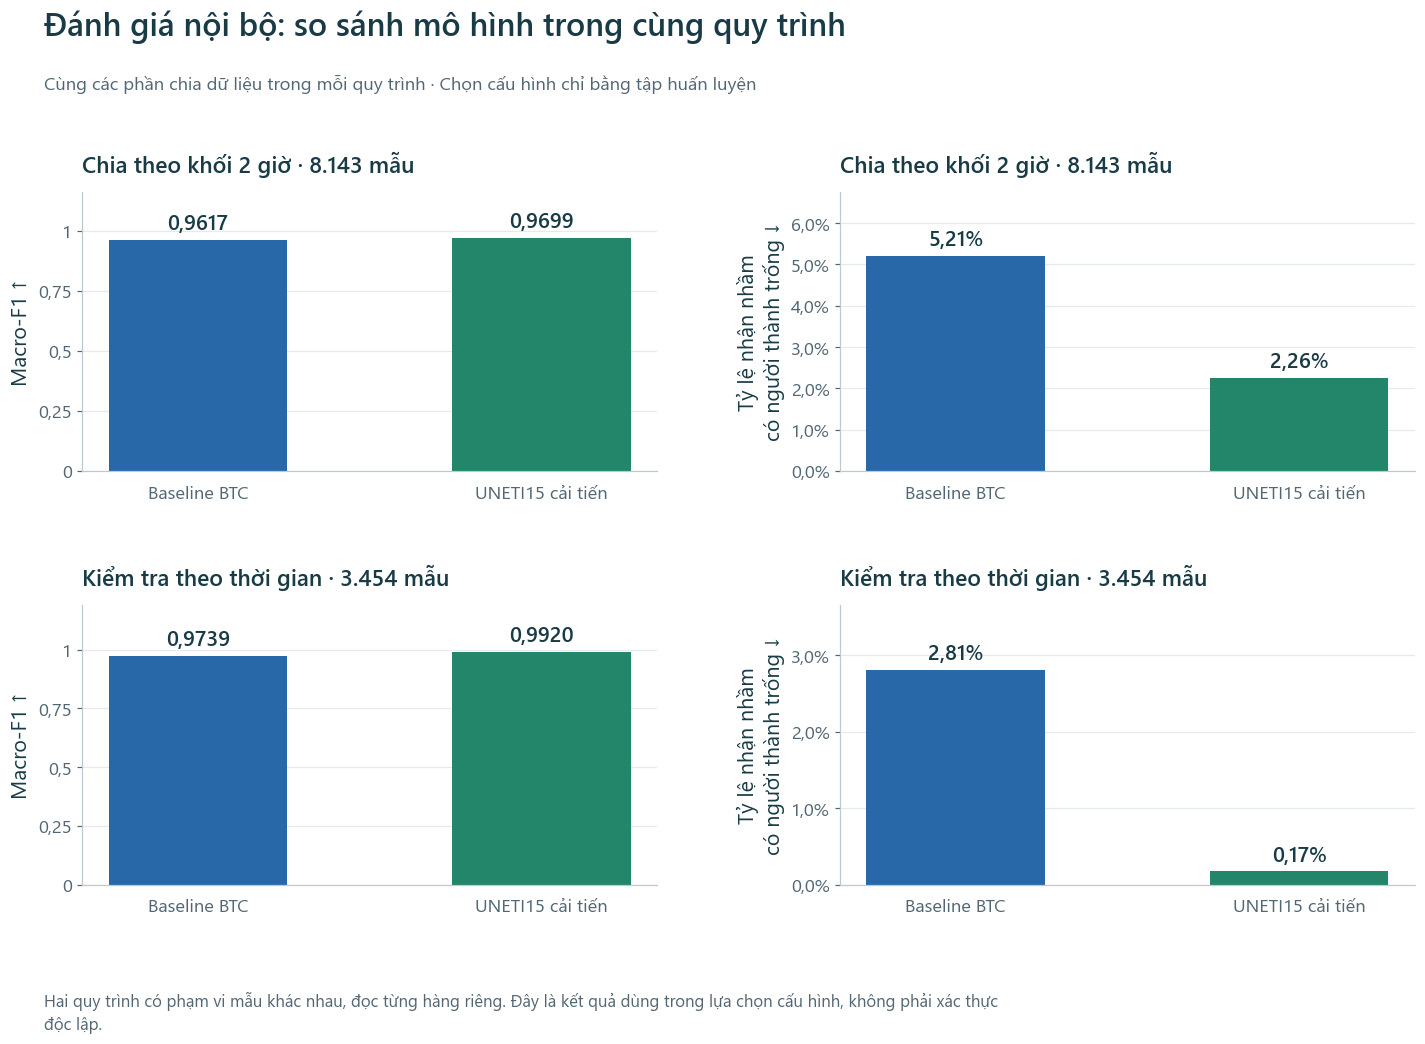

Nhận xét: Macro-F1 của cấu hình chọn ở CV khối hai giờ là 0,9699, ở kiểm tra theo thời gian là 0,9920. Phạm vi mẫu khác nhau, không coi là cùng phép đo.
Ablation: đối chiếu grouped/temporal F1 và FER; cấu hình đã chọn không nhất thiết tốt nhất ở mọi cột.
Temporal folds loại ngày không đủ hai lớp theo điều kiện gốc; không đại diện đầy đủ mọi ngày vận hành.


In [19]:
# Bước 19
# Tận dụng kết quả search: hai mô hình, mỗi mô hình cùng điều kiện trong từng protocol.
cv_comparison_df = pd.concat([
    lr_grouped_summary.loc[lr_grouped_summary["model"].isin(["BTC Logistic Regression", best_lr_name])],
    lr_temporal_summary.loc[lr_temporal_summary["model"].isin(["BTC Logistic Regression", best_lr_name])],
], ignore_index=True)
cv_comparison_df["display_model"] = cv_comparison_df["model"].replace({best_lr_name: best_lr_name.replace("poly=1", "polynomial_degree=2").replace("poly=0", "polynomial_disabled")})
display(cv_comparison_df[["protocol", "display_model", "evaluated_samples", "macro_f1", "false_empty_rate", "FN", "FP"]].round(6))
fig = charts.cv_comparison(cv_comparison_df, best_lr_name)
save_figure("07_logistic_cv_protocol_comparison.png", "07 · So sánh hai quy trình CV",
            "Mỗi hàng là một quy trình riêng; so sánh baseline và cải tiến trong cùng hàng, cùng các phần chia dữ liệu.", fig)
plt.show(); plt.close(fig)
selected_cv = lr_selection_df.loc[lr_selection_df.model == best_lr_name].iloc[0]
print(f"Nhận xét: Macro-F1 của cấu hình chọn ở CV khối hai giờ là {charts.number(selected_cv.grouped_f1,4)}, ở kiểm tra theo thời gian là {charts.number(selected_cv.temporal_f1,4)}. Phạm vi mẫu khác nhau, không coi là cùng phép đo.")
print("Ablation: đối chiếu grouped/temporal F1 và FER; cấu hình đã chọn không nhất thiết tốt nhất ở mọi cột.")
print("Temporal folds loại ngày không đủ hai lớp theo điều kiện gốc; không đại diện đầy đủ mọi ngày vận hành.")

cv_fold_results = pd.concat([lr_grouped_folds, lr_temporal_folds], ignore_index=True)
cv_fold_results = cv_fold_results.loc[cv_fold_results.model.isin(["BTC Logistic Regression", best_lr_name])].drop(columns=["fit_seconds"], errors="ignore")
cv_fold_results.to_csv(RESULTS_DIR / "cv_fold_results.csv", index=False, encoding="utf-8-sig")


### Fit lại cấu hình đã chọn và kiểm tra mô hình

Chỉ fit trên train. Bản tái lập được serialize/reload trong bộ nhớ; metadata đối chiếu gộp vào `results/notebook_run_summary.json`. Đối chiếu cấu hình và xác suất với artifact UNETI15 đang phục vụ ứng dụng; các khác biệt được hiển thị thành báo cáo và làm dừng quy trình thay vì âm thầm thay artifact.

In [20]:
# Bước 20
#
# Training data: datatraining.txt only
# Do not overwrite official BTC baseline

print("=" * 65)
print("FINAL LOGISTIC REGRESSION TRAINING")
print("=" * 65)

# 1. Lay dung cau hinh duoc chon
optimized_lr = clone(
    lr_candidates[best_lr_name]
)

print("Training model:", best_lr_name)
print("Training samples:", len(X_train))
print("Features:", FEATURES)

# 2. Huan luyen tren toan bo training
start_time = time.perf_counter()

optimized_lr.fit(
    X_train,
    y_train
)

training_seconds = time.perf_counter() - start_time

# 3. Kiem tra mo hinh
assert list(optimized_lr.classes_) == [0, 1]

# Kiểm tra serialize/reload trong bộ nhớ, không tạo thêm bản trọng số.
from io import BytesIO
model_buffer = BytesIO()
joblib.dump(optimized_lr, model_buffer)
model_buffer.seek(0)

# 5. Lay chi so CV cua model duoc chon
selected_cv_result = lr_selection_df.loc[
    lr_selection_df["model"] == best_lr_name
].iloc[0]

# 6. Luu metadata
optimized_metadata = {
    "model_name": best_lr_name,
    "display_model_name": best_lr_name.replace("poly=1", "polynomial_degree=2"),
    "polynomial_enabled": selected_has_poly,
    "polynomial_degree": 2 if selected_has_poly else None,
    "algorithm": "Logistic Regression",
    "training_dataset": "datatraining.txt",
    "training_samples": len(X_train),
    "features": FEATURES,
    "target": TARGET,
    "random_seed": SEED,
    "selection_protocol": (
        "Grouped 2-hour CV + Chronological Robustness"
    ),
    "grouped_cv_macro_f1": float(
        selected_cv_result["grouped_f1"]
    ),
    "grouped_cv_false_empty_rate": float(
        selected_cv_result["grouped_fer"]
    ),
    "temporal_cv_macro_f1": float(
        selected_cv_result["temporal_f1"]
    ),
    "temporal_cv_false_empty_rate": float(
        selected_cv_result["temporal_fer"]
    ),
    "training_seconds": float(training_seconds),
    "model_storage": "in_memory_reproduction",
    "sklearn_version": version("scikit-learn")
}

print("\nTRAINING COMPLETED")
print("Model:", best_lr_name)
print(f"Training time: {training_seconds:.3f}s")
print("Mô hình tái lập: bộ nhớ của kernel")
print("Metadata tái lập được gộp trong notebook_run_summary.json")


FINAL LOGISTIC REGRESSION TRAINING
Training model: LR | poly=1 | C=0.3 | cw=balanced
Training samples: 8143
Features: ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']

TRAINING COMPLETED
Model: LR | poly=1 | C=0.3 | cw=balanced
Training time: 0.044s
Mô hình tái lập: bộ nhớ của kernel
Metadata tái lập được gộp trong notebook_run_summary.json


In [21]:
# Bước 21
print("=" * 65)
print("FINAL MODEL VERIFICATION")
print("=" * 65)

# Nạp lại từ buffer trong bộ nhớ rồi đối chiếu xác suất và nhãn.
model_buffer.seek(0)
optimized_lr_loaded = joblib.load(model_buffer)

# 3. Lay 10 mau training de kiem tra
sample_X = X_train.iloc[:10].copy()

# 4. So sanh xac suat truoc va sau khi luu
original_probabilities = optimized_lr.predict_proba(
    sample_X
)

loaded_probabilities = optimized_lr_loaded.predict_proba(
    sample_X
)

np.testing.assert_allclose(
    original_probabilities,
    loaded_probabilities,
    rtol=1e-10,
    atol=1e-12
)

# 5. Kiem tra nhan du doan
original_predictions = optimized_lr.predict(
    sample_X
)

loaded_predictions = optimized_lr_loaded.predict(
    sample_X
)

assert np.array_equal(
    original_predictions,
    loaded_predictions
)

# 6. Hien thi mau du doan
occupied_index = list(
    optimized_lr_loaded.classes_
).index(1)

verification_df = sample_X.copy()

verification_df["actual"] = (
    y_train.iloc[:10].to_numpy()
)

verification_df["prediction"] = loaded_predictions

verification_df["probability_occupied"] = (
    loaded_probabilities[:, occupied_index]
)

print("MODEL RELOAD: SUCCESS")
print("PREDICTIONS MATCH: TRUE")

display(verification_df.round(6))

print("Đã kiểm tra serialize/reload trong bộ nhớ, không xuất bản trọng số dư.")


FINAL MODEL VERIFICATION
MODEL RELOAD: SUCCESS
PREDICTIONS MATCH: TRUE


,Temperature,Humidity,Light,CO2,HumidityRatio,actual,prediction,probability_occupied
1,23.180000,27.272000,426.000000,721.250000,0.004793,1,1,0.688127
2,23.150000,27.267500,429.500000,714.000000,0.004783,1,1,0.699471
3,23.150000,27.245000,426.000000,713.500000,0.004779,1,1,0.684172
4,23.150000,27.200000,426.000000,708.250000,0.004772,1,1,0.675234
5,23.100000,27.200000,426.000000,704.500000,0.004757,1,1,0.684054
6,23.100000,27.200000,419.000000,701.000000,0.004757,1,1,0.647837
7,23.100000,27.200000,419.000000,701.666667,0.004757,1,1,0.649006
8,23.100000,27.200000,419.000000,699.000000,0.004757,1,1,0.644318
9,23.100000,27.200000,419.000000,689.333333,0.004757,1,1,0.627089
10,23.075000,27.175000,419.000000,688.000000,0.004745,1,1,0.632740


Đã kiểm tra serialize/reload trong bộ nhớ, không xuất bản trọng số dư.


In [22]:
# Bước 22
app_optimized_path = ROOT / "model/logistic_optimized.joblib"
app_optimized = joblib.load(app_optimized_path)
app_metadata = json.loads((ROOT / "model/logistic_optimized_metadata.json").read_text(encoding="utf-8"))
assert list(app_optimized.feature_names_in_) == FEATURES
assert set(app_optimized.classes_) == {0, 1}
app_classifier = app_optimized.named_steps["logisticregression"]
train_probability_delta = float(np.max(np.abs(app_optimized.predict_proba(X_train) - optimized_lr_loaded.predict_proba(X_train))))
reproduction_report = {
    "selected_model": best_lr_name, "published_model": app_metadata["model_name"],
    "max_absolute_train_probability_difference": train_probability_delta,
    "class_weight_matches": app_classifier.class_weight == selected_weight,
    "C_matches": bool(np.isclose(app_classifier.C, selected_c)),
    "polynomial_degree_matches": app_optimized.named_steps["polynomialfeatures"].degree == 2,
    "research_model": "in_memory_reproduction",
    "application_model": app_optimized_path.relative_to(ROOT).as_posix(),
}
display(pd.DataFrame([reproduction_report]))
assert all(reproduction_report[k] for k in ["class_weight_matches", "C_matches", "polynomial_degree_matches"])
np.testing.assert_allclose(app_optimized.predict_proba(X_train), optimized_lr_loaded.predict_proba(X_train), rtol=1e-10, atol=1e-12)
assert best_lr_name == app_metadata["model_name"], "Lựa chọn tái lập khác mô hình đã công bố: xem bảng đối chiếu ở trên."


,selected_model,published_model,max_absolute_train_probability_difference,class_weight_matches,C_matches,polynomial_degree_matches,research_model,application_model
0,LR | poly=1 | C=0.3 | cw=balanced,LR | poly=1 | C=0.3 | cw=balanced,0.000000,True,True,True,in_memory_reproduction,model/logistic_optimized.joblib


## D. So sánh cùng điều kiện — Validation chính thức

Cùng 8.143 mẫu train, cùng năm cảm biến, cùng `datatest.txt` và ngưỡng phân loại mặc định `predict` của Logistic. Báo cáo kết quả **hai artifact ứng dụng**; kiểm tra bản fit tái lập có cùng dự đoán/xác suất trên validation. Không dùng validation để chọn lại cấu hình.

Split chính thức có thời gian validation sớm hơn train; giữ đúng split BTC nhưng không gọi đây là phép kiểm tra dự báo tương lai. Các số CV ở phần C có protocol khác, không dùng để xếp hạng trực tiếp với số validation ở đây.

In [23]:
# Bước 23
#
# Validation: datatest.txt
# Khong dung datatest2.txt
# Khong fit model tren validation

print("=" * 65)
print("LOAD VALIDATION DATA")
print("=" * 65)

# 1. Doc du lieu
val_df = pd.read_csv(
    VAL_PATH,
    index_col=0
)

# 2. Kiem tra cot bat buoc
missing_val_columns = [
    column
    for column in ["date"] + FEATURES + [TARGET]
    if column not in val_df.columns
]

if missing_val_columns:
    raise ValueError(
        f"Validation thieu cot: {missing_val_columns}"
    )

# 3. Chuyen kieu du lieu
val_df["date"] = pd.to_datetime(
    val_df["date"],
    errors="coerce"
)

for feature in FEATURES:
    val_df[feature] = pd.to_numeric(
        val_df[feature],
        errors="coerce"
    )

val_df[TARGET] = pd.to_numeric(
    val_df[TARGET],
    errors="raise"
)

# 4. Kiem tra gia tri hop le
assert val_df["date"].notna().all()
assert val_df[TARGET].isin([0, 1]).all()

assert np.isfinite(
    val_df[FEATURES].to_numpy(dtype=float)
).all(), "Validation co gia tri cam bien khong hop le."

# 5. Sap xep theo thoi gian
val_df = (
    val_df
    .sort_values("date", kind="stable")
    .reset_index(drop=True)
)

# 6. Tao X_val va y_val
X_val = val_df[FEATURES].copy()
y_val = val_df[TARGET].astype(int).copy()

# 7. Bao cao
print("Validation shape:", val_df.shape)
print("Feature shape   :", X_val.shape)

print("\nClass distribution:")
print(y_val.value_counts().sort_index())

print("\nTime range:")
print("Start:", val_df["date"].min())
print("End  :", val_df["date"].max())

assert len(val_df) == 2665, (
    "So mau khong khop tap datatest.txt cua BTC."
)


LOAD VALIDATION DATA


Validation shape: (2665, 7)
Feature shape   : (2665, 5)

Class distribution:
Occupancy
0    1693
1     972
Name: count, dtype: int64

Time range:
Start: 2015-02-02 14:19:00
End  : 2015-02-04 10:43:00


In [24]:
# Bước 24
validation_reproduction = {}
for name, published, reproduced in [
    ("BTC", btc_model, btc_reproduced), ("UNETI15", app_optimized, optimized_lr_loaded),
]:
    published_p, reproduced_p = published.predict_proba(X_val), reproduced.predict_proba(X_val)
    validation_reproduction[name] = {"max_absolute_probability_difference": float(np.max(np.abs(published_p-reproduced_p))),
                                     "predictions_match": bool(np.array_equal(published.predict(X_val), reproduced.predict(X_val)))}
for published, reproduced in [(btc_model, btc_reproduced), (app_optimized, optimized_lr_loaded)]:
    np.testing.assert_allclose(published.predict_proba(X_val), reproduced.predict_proba(X_val), rtol=1e-10, atol=1e-12)
    assert np.array_equal(published.predict(X_val), reproduced.predict(X_val))
print("Hai mô hình nghiên cứu tái lập khớp hai artifact ứng dụng trên validation.")


Hai mô hình nghiên cứu tái lập khớp hai artifact ứng dụng trên validation.


LOGISTIC REGRESSION VALIDATION


,model,accuracy,macro_f1,f1_empty,f1_occupied,recall_occupied,false_empty_rate,TN,FP,FN,TP
0,BTC Logistic Regression,0.977111,0.975547,0.981731,0.969362,0.992798,0.007202,1639,54,7,965
1,Optimized Logistic Regression,0.978612,0.977178,0.982898,0.971457,0.997942,0.002058,1638,55,2,970



DIFFERENCE: OPTIMIZED - BTC
Macro-F1: +0.001631
False Empty Rate: -0.005144
False Empty count: 7 -> 2
False Occupied count: 54 -> 55


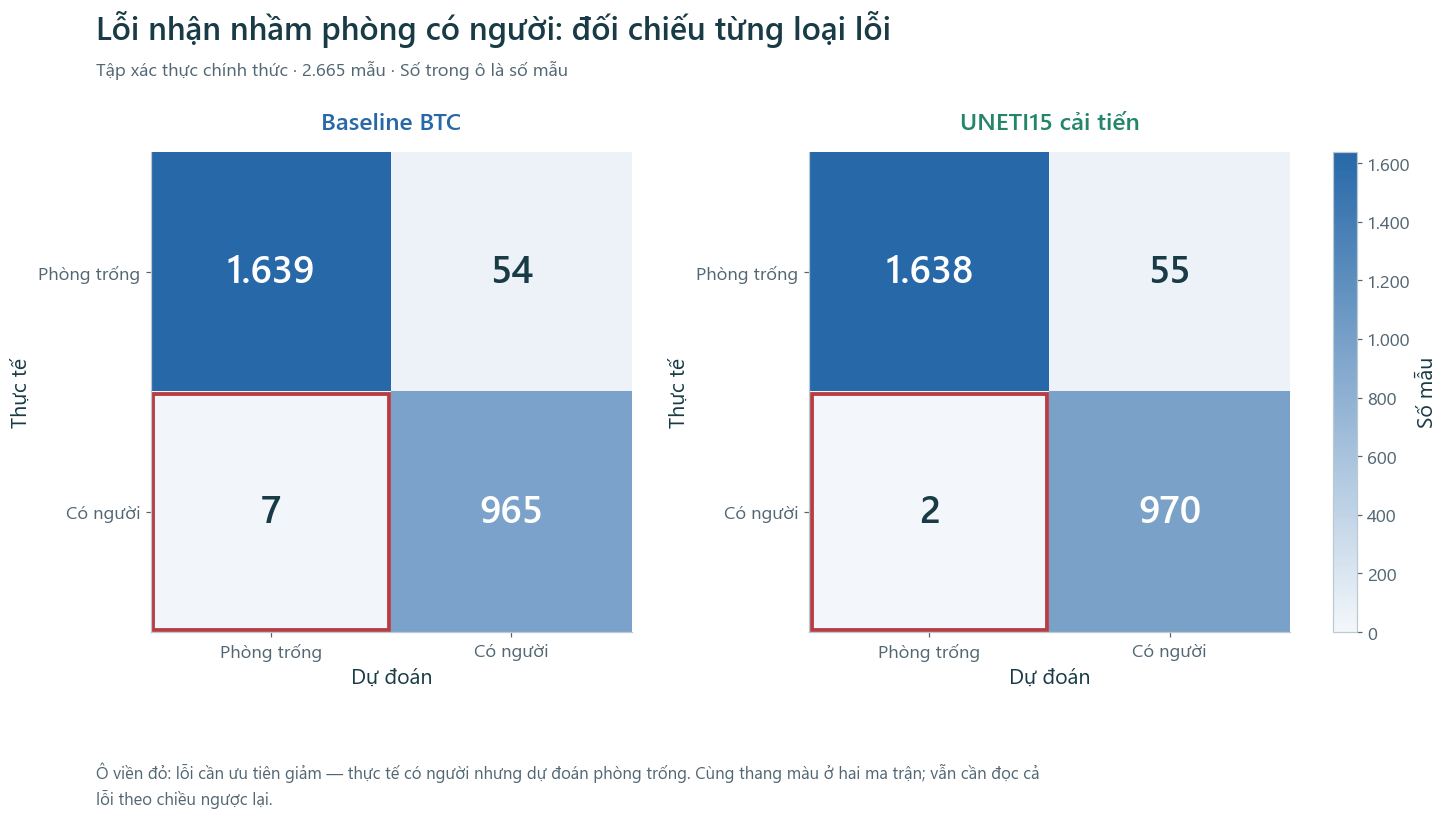

Nhận xét: lỗi cần ưu tiên giảm là ô viền đỏ, từ 7 xuống 2 mẫu; vẫn có lỗi mới và sự đánh đổi theo chiều ngược lại.


In [25]:
# Bước 25
#
# BTC Logistic Regression vs Optimized Logistic Regression
# All metrics calculated on the same validation data.

print("=" * 65)
print("LOGISTIC REGRESSION VALIDATION")
print("=" * 65)

# 1. Hai mo hinh da huan luyen
validation_models = {
    "BTC Logistic Regression": btc_model,
    "Optimized Logistic Regression": app_optimized
}

validation_records = []

# 2. Luu du doan cua tung mau de phan tich loi
validation_predictions_df = val_df[
    ["date"] + FEATURES + [TARGET]
].copy()

validation_predictions_df = validation_predictions_df.rename(
    columns={TARGET: "actual"}
)

prediction_columns = {
    "BTC Logistic Regression": "btc_prediction",
    "Optimized Logistic Regression": "optimized_prediction"
}

probability_columns = {
    "BTC Logistic Regression": "btc_probability",
    "Optimized Logistic Regression": "optimized_probability"
}

# 3. Du doan va tinh chi so
for model_name, model in validation_models.items():

    predictions = model.predict(X_val)

    occupied_index = list(model.classes_).index(1)

    probabilities = model.predict_proba(X_val)[
        :, occupied_index
    ]

    metrics = calculate_classification_metrics(
        y_val,
        predictions
    )

    validation_records.append({
        "model": model_name,
        "samples": len(y_val),
        **metrics
    })

    validation_predictions_df[
        prediction_columns[model_name]
    ] = predictions

    validation_predictions_df[
        probability_columns[model_name]
    ] = probabilities

# 4. Bang so sanh
validation_comparison_df = pd.DataFrame(
    validation_records
)

display(
    validation_comparison_df[
        [
            "model",
            "accuracy",
            "macro_f1",
            "f1_empty",
            "f1_occupied",
            "recall_occupied",
            "false_empty_rate",
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ].round(6)
)

# 5. Phan tich chenh lech
btc_row = validation_comparison_df.loc[
    validation_comparison_df["model"] ==
    "BTC Logistic Regression"
].iloc[0]

optimized_row = validation_comparison_df.loc[
    validation_comparison_df["model"] ==
    "Optimized Logistic Regression"
].iloc[0]

print("\nDIFFERENCE: OPTIMIZED - BTC")

print(
    "Macro-F1:",
    f"{optimized_row['macro_f1'] - btc_row['macro_f1']:+.6f}"
)

print(
    "False Empty Rate:",
    f"{optimized_row['false_empty_rate'] - btc_row['false_empty_rate']:+.6f}"
)

print(
    "False Empty count:",
    f"{int(btc_row['FN'])} -> {int(optimized_row['FN'])}"
)

print(
    "False Occupied count:",
    f"{int(btc_row['FP'])} -> {int(optimized_row['FP'])}"
)

# Hai ma trận dùng cùng thứ tự lớp và cùng thang màu; nhấn ô lỗi bỏ sót có người.
fig = charts.confusion_matrices(y_val, [validation_predictions_df.btc_prediction, validation_predictions_df.optimized_prediction])
save_figure("08_logistic_validation_confusion_matrix.png", "08 · Hai ma trận nhầm lẫn",
            f"Lỗi có người → phòng trống: {int(btc_row.FN)} → {int(optimized_row.FN)}; lỗi ngược lại {int(btc_row.FP)} → {int(optimized_row.FP)}.", fig)
plt.show(); plt.close(fig)
print(f"Nhận xét: lỗi cần ưu tiên giảm là ô viền đỏ, từ {int(btc_row.FN)} xuống {int(optimized_row.FN)} mẫu; vẫn có lỗi mới và sự đánh đổi theo chiều ngược lại.")

# 7. Luu ket qua
validation_comparison_df.to_csv(
    RESULTS_DIR / "logistic_validation_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)



Trên validation này: FN 7 → 2; giảm tương đối 71.43%.
False Empty Rate 0.7202% → 0.2058%; FP 54 → 55.
Kết quả trên một tập xác thực không bảo đảm cùng mức cải thiện tại phòng học mới.


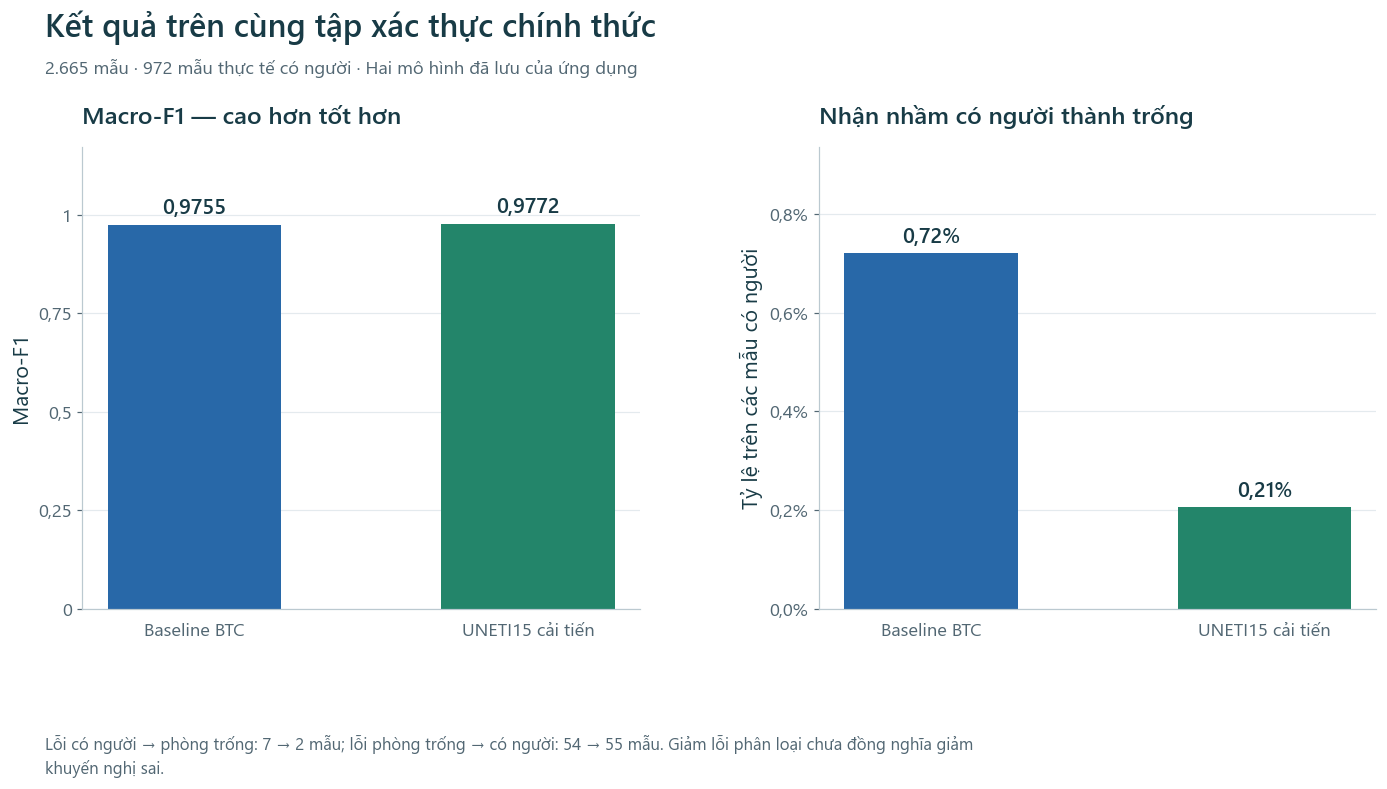

In [26]:
# Bước 26
fn_reduction = int(btc_row["FN"] - optimized_row["FN"])
relative_fn_reduction = fn_reduction / btc_row["FN"] if btc_row["FN"] else np.nan
print(f"Trên validation này: FN {int(btc_row['FN'])} → {int(optimized_row['FN'])}; giảm tương đối {relative_fn_reduction:.2%}.")
print(f"False Empty Rate {btc_row['false_empty_rate']:.4%} → {optimized_row['false_empty_rate']:.4%}; FP {int(btc_row['FP'])} → {int(optimized_row['FP'])}.")
print("Kết quả trên một tập xác thực không bảo đảm cùng mức cải thiện tại phòng học mới.")

fig = charts.validation_comparison(validation_comparison_df)
save_figure("10_validation_model_comparison.png", "10 · Kết quả validation chính thức",
            f"Trên cùng {len(y_val)} mẫu: đọc Macro-F1 và tỷ lệ lỗi có người → phòng trống; không trộn số CV vào hình này.", fig)
plt.show(); plt.close(fig)


## E. Phân tích lỗi — Mẫu được sửa và lỗi mới

Đối chiếu cùng từng hàng, theo ngày và quanh thời điểm lỗi. Phân biệt quan sát (giá trị tín hiệu, nhãn, xác suất) với giả thuyết nguyên nhân. Tín hiệu vượt khoảng train cho biết giới hạn dữ liệu đã quan sát, không tự chứng minh lý do dự đoán sai.

In [27]:
# Bước 27
print("=" * 65)
print("VALIDATION ERROR ANALYSIS")
print("=" * 65)

# 1. Tao cot ngay
validation_predictions_df["day"] = (
    validation_predictions_df["date"].dt.date
)

# 2. Thong ke loi theo ngay
daily_error_records = []

for day, day_data in validation_predictions_df.groupby("day"):

    for model_name, prediction_col in prediction_columns.items():

        metrics = calculate_classification_metrics(
            day_data["actual"],
            day_data[prediction_col]
        )

        daily_error_records.append({
            "day": str(day),
            "model": model_name,
            "samples": len(day_data),
            "occupied_samples": int(
                (day_data["actual"] == 1).sum()
            ),
            "macro_f1": metrics["macro_f1"],
            "false_empty_rate": metrics["false_empty_rate"],
            "FN": metrics["FN"],
            "FP": metrics["FP"]
        })

daily_error_df = pd.DataFrame(
    daily_error_records
)

print("\n1. ERROR ANALYSIS BY DAY")

display(daily_error_df.round(6))

# 3. Xac dinh nhung mau False Empty
btc_fn_mask = (
    (validation_predictions_df["actual"] == 1)
    &
    (validation_predictions_df["btc_prediction"] == 0)
)

optimized_fn_mask = (
    (validation_predictions_df["actual"] == 1)
    &
    (validation_predictions_df["optimized_prediction"] == 0)
)

# 4. So sanh tap loi
error_overlap_df = pd.DataFrame([{
    "BTC False Empty": int(btc_fn_mask.sum()),
    "Optimized False Empty": int(optimized_fn_mask.sum()),
    "Both models wrong": int(
        (btc_fn_mask & optimized_fn_mask).sum()
    ),
    "BTC only wrong": int(
        (btc_fn_mask & ~optimized_fn_mask).sum()
    ),
    "Optimized only wrong": int(
        (~btc_fn_mask & optimized_fn_mask).sum()
    )
}])

print("\n2. FALSE EMPTY OVERLAP")

display(error_overlap_df)

# 5. Xem chi tiet cac mau co it nhat mot model bao nham
fn_cases_df = validation_predictions_df.loc[
    btc_fn_mask | optimized_fn_mask,
    [
        "date",
        "Temperature",
        "Humidity",
        "Light",
        "CO2",
        "HumidityRatio",
        "actual",
        "btc_prediction",
        "optimized_prediction",
        "btc_probability",
        "optimized_probability"
    ]
].copy()

print("\n3. FALSE EMPTY CASES")

display(fn_cases_df.round(6))

# 6. Luu ket qua




VALIDATION ERROR ANALYSIS

1. ERROR ANALYSIS BY DAY


,day,model,samples,occupied_samples,macro_f1,false_empty_rate,FN,FP
0,2015-02-02,BTC Logistic Regression,581,203,0.948011,0.024631,5,23
1,2015-02-02,Optimized Logistic Regression,581,203,0.957505,0.000000,0,23
2,2015-02-03,BTC Logistic Regression,1440,599,0.988603,0.001669,1,15
3,2015-02-03,Optimized Logistic Regression,1440,599,0.987894,0.001669,1,16
4,2015-02-04,BTC Logistic Regression,644,170,0.966946,0.005882,1,16
5,2015-02-04,Optimized Logistic Regression,644,170,0.966946,0.005882,1,16



2. FALSE EMPTY OVERLAP


,BTC False Empty,Optimized False Empty,Both models wrong,BTC only wrong,Optimized only wrong
0,7,2,1,6,1



3. FALSE EMPTY CASES


,date,Temperature,Humidity,Light,CO2,HumidityRatio,actual,btc_prediction,optimized_prediction,btc_probability,optimized_probability
4,2015-02-02 14:23:00,23.754000,26.200000,488.600000,779.000000,0.004767,1,0,1,0.493771,0.826235
8,2015-02-02 14:26:59,23.754000,26.350000,476.000000,803.200000,0.004794,1,0,1,0.465400,0.822374
14,2015-02-02 14:32:59,23.700000,26.774000,464.000000,852.400000,0.004856,1,0,1,0.492922,0.856234
16,2015-02-02 14:35:00,23.700000,26.972500,455.000000,880.000000,0.004892,1,0,1,0.487153,0.862535
225,2015-02-02 18:04:00,22.390000,25.092500,310.250000,809.000000,0.004200,1,0,1,0.178412,0.550244
1037,2015-02-03 07:36:00,20.290000,22.790000,217.200000,441.600000,0.003349,1,0,0,0.062943,0.167617
2479,2015-02-04 07:38:00,20.390000,23.700000,311.750000,474.750000,0.003505,1,0,1,0.316724,0.621348
2602,2015-02-04 09:40:59,22.700000,25.500000,1697.250000,951.750000,0.004350,1,1,0,1.000000,0.260837


In [28]:
# Bước 28
train_ranges = X_train.agg(["min", "max"])
error_context_parts = []
for error_idx in np.flatnonzero((btc_fn_mask | optimized_fn_mask).to_numpy()):
    context = validation_predictions_df.iloc[max(0, error_idx-3):min(len(val_df), error_idx+4)].copy()
    context["focus_timestamp"] = validation_predictions_df.iloc[error_idx]["date"]
    context["is_focus"] = context.index == error_idx
    error_context_parts.append(context)
error_context_df = pd.concat(error_context_parts, ignore_index=True) if error_context_parts else pd.DataFrame()
fn_cases_df["outside_train_range"] = fn_cases_df.apply(
    lambda row: ", ".join(f for f in FEATURES if row[f] < train_ranges.loc["min", f] or row[f] > train_ranges.loc["max", f]), axis=1)
display(fn_cases_df[["date", "actual", "btc_prediction", "optimized_prediction", "btc_probability", "optimized_probability", "outside_train_range"]])
fn_cases_df.to_csv(RESULTS_DIR / "validation_false_empty_cases.csv", index=False, encoding="utf-8-sig")
print("Mẫu vượt khoảng train là quan sát mô tả; chưa chứng minh cảm biến đó gây ra lỗi.")
print("Giảm FN có thể đi kèm tăng FP; cần báo cáo cả hai thay vì chỉ chọn chỉ số thuận lợi.")


,date,actual,btc_prediction,optimized_prediction,btc_probability,optimized_probability,outside_train_range
4,2015-02-02 14:23:00,1,0,1,0.493771,0.826235,Temperature
8,2015-02-02 14:26:59,1,0,1,0.465400,0.822374,Temperature
14,2015-02-02 14:32:59,1,0,1,0.492922,0.856234,Temperature
16,2015-02-02 14:35:00,1,0,1,0.487153,0.862535,Temperature
225,2015-02-02 18:04:00,1,0,1,0.178412,0.550244,
1037,2015-02-03 07:36:00,1,0,0,0.062943,0.167617,
2479,2015-02-04 07:38:00,1,0,1,0.316724,0.621348,
2602,2015-02-04 09:40:59,1,1,0,1.000000,0.260837,Light


Mẫu vượt khoảng train là quan sát mô tả; chưa chứng minh cảm biến đó gây ra lỗi.
Giảm FN có thể đi kèm tăng FP; cần báo cáo cả hai thay vì chỉ chọn chỉ số thuận lợi.


## F. Cải tiến cảnh báo — Bằng chứng chuỗi và kiểm thử gián đoạn

Ba phương án: BTC + logic gốc; Logistic cải tiến + logic gốc; Logistic cải tiến + reset khi thời gian không tăng hoặc khoảng cách **>120 giây**. Cả ba giữ **P(có người) < 0,20** trong ít nhất **ba mẫu liên tiếp**. Ba mẫu không đồng nghĩa ba phút.

Phân loại dùng nhãn `predict`; điều kiện khuyến nghị dùng xác suất và chuỗi. **FN không đồng nghĩa khuyến nghị sai**. Mô phỏng offline dưới đây xét dữ liệu hợp lệ theo timestamp; backend còn xử lý mẫu lỗi, hết hạn nhập tay, bằng chứng và xác nhận phòng/thiết bị. Không dùng thời gian đồng hồ hiện tại để làm hết hạn chuỗi CSV lịch sử. Không điều khiển điện thật.

Đơn vị báo cáo:
- `correct_alert_samples`: số hàng có khuyến nghị và nhãn thật là trống.
- `unsafe_alert_samples`: số hàng có khuyến nghị nhưng nhãn thật có người.
- `unsafe_rate_among_occupied`: số hàng khuyến nghị sai / tổng hàng có người.
- `empty_coverage`: số hàng khuyến nghị đúng / tổng hàng phòng trống.
- `alert_precision`: số hàng khuyến nghị đúng / tổng hàng có khuyến nghị.
- `total_alert_episodes`: số đợt khuyến nghị liên tục; reset thời gian luôn bắt đầu đợt mới. Một đợt sai là đợt chứa ít nhất một hàng có người.

Đây là chỉ số khuyến nghị trên dữ liệu có nhãn, không phải số lần tắt thiết bị hay kWh tiết kiệm.

In [29]:
# Bước 29
ALERT_THRESHOLD = 0.20
ALERT_CONSECUTIVE = 3
ALERT_MAX_GAP_SECONDS = 120

print("=" * 65)
print("ALERT SEQUENCE SIMULATION")
print("=" * 65)


# 1. Ham mo phong logic canh bao
def simulate_alerts(
    probabilities,
    timestamps,
    threshold=0.20,
    consecutive_required=3,
    max_gap_seconds=None
):
    probabilities = np.asarray(probabilities, dtype=float)

    timestamps = pd.Series(
        pd.to_datetime(timestamps)
    ).reset_index(drop=True)

    if len(probabilities) != len(timestamps):
        raise ValueError("So luong xac suat va thoi gian khong khop.")

    if not np.isfinite(probabilities).all():
        raise ValueError("Xac suat du doan khong hop le.")

    if ((probabilities < 0) | (probabilities > 1)).any():
        raise ValueError("Xac suat phai nam trong [0, 1].")

    if timestamps.isna().any():
        raise ValueError("Timestamp co gia tri khong hop le.")

    time_gaps = timestamps.diff().dt.total_seconds()

    # Giữ thứ tự đầu vào; timestamp không tăng sẽ reset ở phương án có gap check.

    alerts = np.zeros(len(probabilities), dtype=bool)
    streaks = np.zeros(len(probabilities), dtype=int)

    low_count = 0

    for i, probability in enumerate(probabilities):

        if max_gap_seconds is not None and i > 0:
            gap = time_gaps.iloc[i]

            if gap <= 0 or gap > max_gap_seconds:
                low_count = 0

        if probability < threshold:
            low_count += 1
        else:
            low_count = 0

        streaks[i] = low_count
        alerts[i] = low_count >= consecutive_required

    return alerts, streaks


# 2. Du lieu da du doan tai bước trước
alert_actual = validation_predictions_df[
    "actual"
].to_numpy(dtype=int)

alert_timestamps = validation_predictions_df["date"]

btc_probabilities = validation_predictions_df[
    "btc_probability"
].to_numpy(dtype=float)

optimized_probabilities = validation_predictions_df[
    "optimized_probability"
].to_numpy(dtype=float)


# 3. Logic goc BTC
btc_alerts, btc_streaks = simulate_alerts(
    btc_probabilities,
    alert_timestamps,
    threshold=ALERT_THRESHOLD,
    consecutive_required=ALERT_CONSECUTIVE
)


# 4. Logistic cai tien + logic BTC
optimized_alerts, optimized_streaks = simulate_alerts(
    optimized_probabilities,
    alert_timestamps,
    threshold=ALERT_THRESHOLD,
    consecutive_required=ALERT_CONSECUTIVE
)


# 5. Logistic cai tien + kiem tra gian doan
optimized_gap_alerts, optimized_gap_streaks = simulate_alerts(
    optimized_probabilities,
    alert_timestamps,
    threshold=ALERT_THRESHOLD,
    consecutive_required=ALERT_CONSECUTIVE,
    max_gap_seconds=ALERT_MAX_GAP_SECONDS
)


# 6. Kiem tra rang logic gian doan khong tao them canh bao
assert np.all(
    ~optimized_gap_alerts | optimized_alerts
)

# 7. Tong hop du doan
alert_predictions_df = validation_predictions_df[
    ["date", "actual"]
].copy()

alert_predictions_df["btc_alert"] = btc_alerts

alert_predictions_df["optimized_alert"] = optimized_alerts

alert_predictions_df["optimized_gap_alert"] = optimized_gap_alerts

print("Samples:", len(alert_predictions_df))
print("Threshold:", ALERT_THRESHOLD)
print("Consecutive samples:", ALERT_CONSECUTIVE)
print("Max gap:", ALERT_MAX_GAP_SECONDS)


ALERT SEQUENCE SIMULATION
Samples: 2665
Threshold: 0.2
Consecutive samples: 3
Max gap: 120


In [30]:
# Bước 30
def calculate_alert_metrics(
    name,
    alerts,
    actual,
    timestamps=None,
    max_gap_seconds=None
):
    alerts = np.asarray(alerts, dtype=bool)
    actual = np.asarray(actual, dtype=int)

    correct_alerts = int(
        ((alerts == 1) & (actual == 0)).sum()
    )

    unsafe_alerts = int(
        ((alerts == 1) & (actual == 1)).sum()
    )

    total_alerts = int(alerts.sum())
    total_empty = int((actual == 0).sum())
    total_occupied = int((actual == 1).sum())

    # Tim diem bat dau va ket thuc cac dot canh bao
    breaks = np.zeros(len(alerts), dtype=bool)
    if len(breaks):
        breaks[0] = True
    if timestamps is not None and max_gap_seconds is not None:
        gaps = pd.Series(pd.to_datetime(timestamps)).diff().dt.total_seconds().to_numpy()
        breaks[1:] = (gaps[1:] <= 0) | (gaps[1:] > max_gap_seconds)
    previous = np.r_[False, alerts[:-1]]
    following = np.r_[alerts[1:], False]
    starts = np.flatnonzero(alerts & (~previous | breaks))
    ends = np.flatnonzero(alerts & (~following | np.r_[breaks[1:], True]))

    unsafe_episodes = 0

    for start, end in zip(starts, ends):
        if np.any(actual[start:end + 1] == 1):
            unsafe_episodes += 1

    return {
        "model": name,
        "correct_alert_samples": correct_alerts,
        "unsafe_alert_samples": unsafe_alerts,
        "unsafe_rate_among_occupied": (
            unsafe_alerts / total_occupied
        ),
        "empty_coverage": (
            correct_alerts / total_empty
        ),
        "alert_precision": (
            correct_alerts / total_alerts
            if total_alerts > 0 else np.nan
        ),
        "total_alert_episodes": len(starts),
        "unsafe_alert_episodes": unsafe_episodes
    }


# 1. Danh gia ba phuong an
alert_results = [
    calculate_alert_metrics(
        "BTC Logistic + Original Alert",
        btc_alerts,
        alert_actual
    ),

    calculate_alert_metrics(
        "Optimized Logistic + Original Alert",
        optimized_alerts,
        alert_actual
    ),

    calculate_alert_metrics(
        "Optimized Logistic + Gap Check",
        optimized_gap_alerts,
        alert_actual,
        timestamps=alert_timestamps,
        max_gap_seconds=ALERT_MAX_GAP_SECONDS
    )
]

# 2. Bang so sanh
alert_comparison_df = pd.DataFrame(alert_results)

print("=" * 65)
print("ALERT PERFORMANCE COMPARISON")
print("=" * 65)

display(alert_comparison_df.round(6))


# 3. Luu ket qua
alert_comparison_df.to_csv(
    RESULTS_DIR / "alert_validation_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)



ALERT PERFORMANCE COMPARISON


,model,correct_alert_samples,unsafe_alert_samples,unsafe_rate_among_occupied,empty_coverage,alert_precision,total_alert_episodes,unsafe_alert_episodes
0,BTC Logistic + Original Alert,1633,1,0.001029,0.964560,0.999388,3,1
1,Optimized Logistic + Original Alert,1631,1,0.001029,0.963379,0.999387,3,1
2,Optimized Logistic + Gap Check,1631,1,0.001029,0.963379,0.999387,3,1


In [31]:
# Bước 31
gaps = pd.Series(pd.to_datetime(alert_timestamps)).diff().dt.total_seconds()
print("Khoảng cách >120 giây trong validation:", int((gaps > ALERT_MAX_GAP_SECONDS).sum()))
print("Timestamp không tăng:", int((gaps.iloc[1:] <= 0).sum()))
if np.array_equal(optimized_alerts, optimized_gap_alerts):
    print("Gap check không thay đổi khuyến nghị trên validation này; tác dụng chức năng được kiểm chứng riêng bên dưới.")
display(alert_comparison_df[["model", "unsafe_alert_samples", "unsafe_rate_among_occupied", "empty_coverage", "total_alert_episodes", "unsafe_alert_episodes"]])
print("Không suy từ giảm FN sang kết luận số khuyến nghị sai đã giảm; đọc trực tiếp bảng khuyến nghị.")


Khoảng cách >120 giây trong validation: 0
Timestamp không tăng: 0
Gap check không thay đổi khuyến nghị trên validation này; tác dụng chức năng được kiểm chứng riêng bên dưới.


,model,unsafe_alert_samples,unsafe_rate_among_occupied,empty_coverage,total_alert_episodes,unsafe_alert_episodes
0,BTC Logistic + Original Alert,1,0.001029,0.964560,3,1
1,Optimized Logistic + Original Alert,1,0.001029,0.963379,3,1
2,Optimized Logistic + Gap Check,1,0.001029,0.963379,3,1


Không suy từ giảm FN sang kết luận số khuyến nghị sai đã giảm; đọc trực tiếp bảng khuyến nghị.


Biểu đồ minh họa xác suất và cảnh báo theo thời gian

ALERT TIMELINE


Selected day: 2015-02-03
Samples: 1440


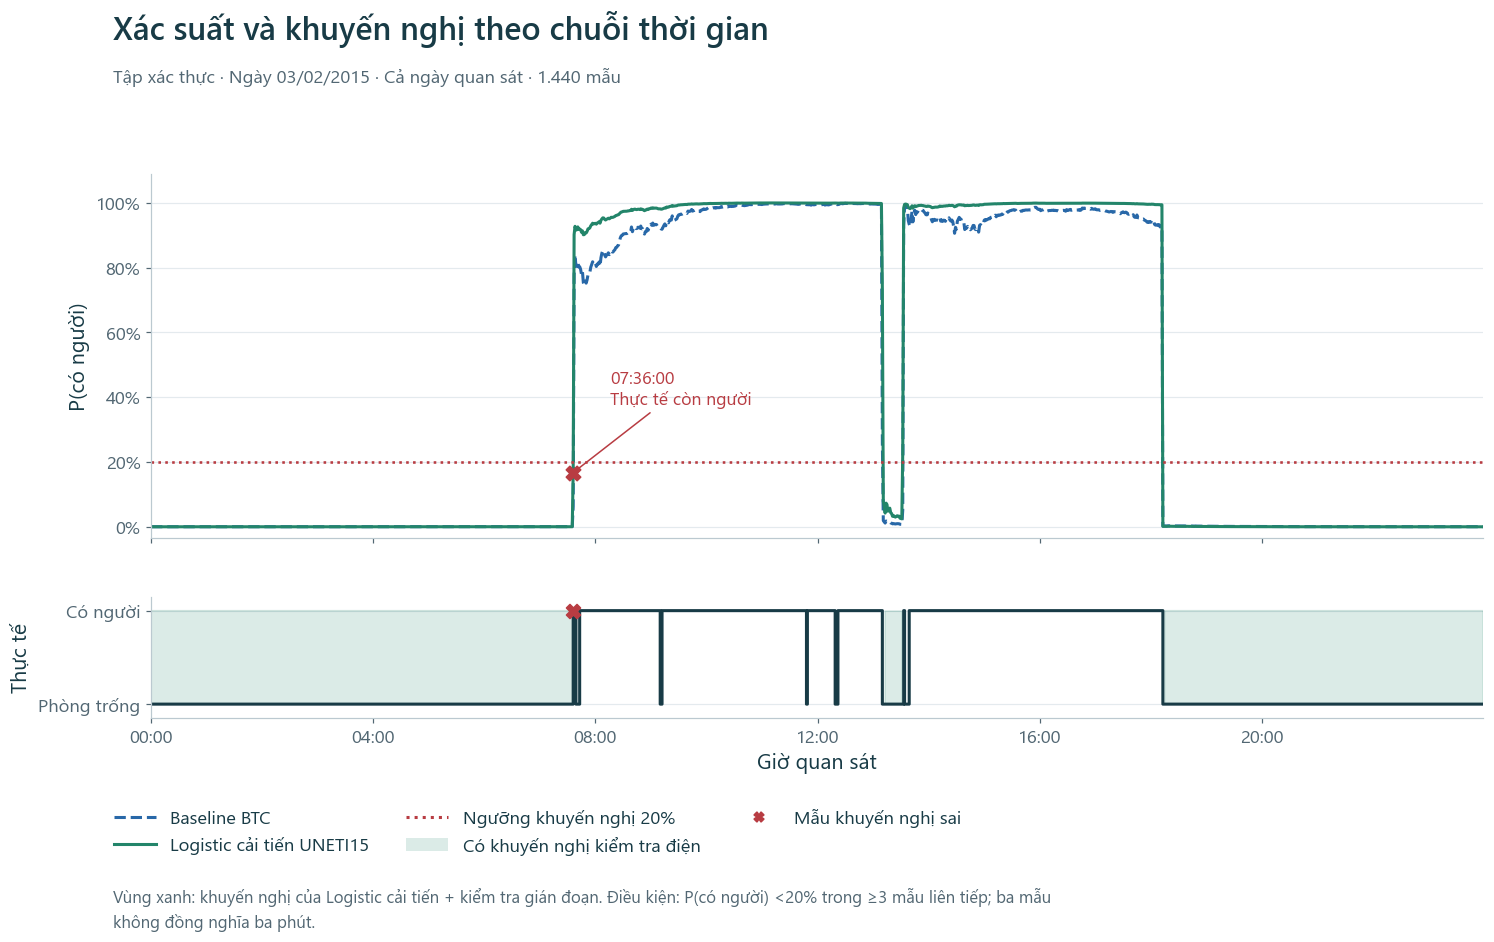

Nhận xét: trong ngày minh họa có 1 mẫu khuyến nghị sai. Giảm lỗi phân loại không tự bảo đảm giảm khuyến nghị sai.


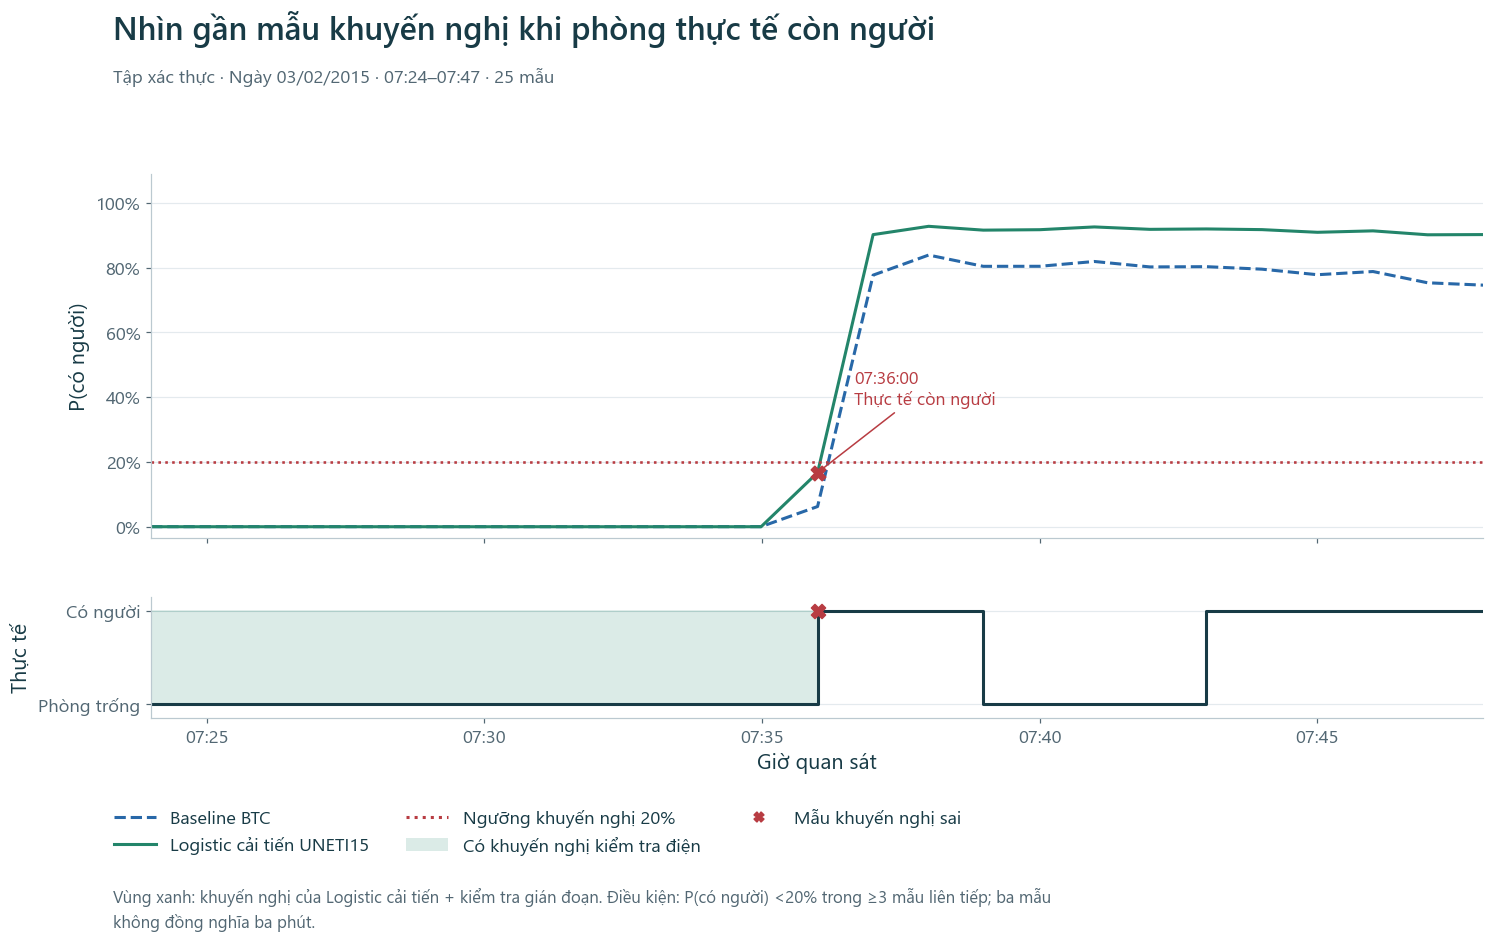

Nhận xét hình phóng to: đây là tình huống sai thực tế của tập xác thực, không phải xác suất giả lập hay minh chứng nguyên nhân.


In [32]:
# Bước 32
print("=" * 65)
print("ALERT TIMELINE")
print("=" * 65)

# 1. Tao bang du lieu cho bieu do
timeline_df = validation_predictions_df[
    ["date", "actual", "btc_probability", "optimized_probability"]
].copy()

timeline_df["btc_alert"] = btc_alerts
timeline_df["optimized_alert"] = optimized_alerts
timeline_df["optimized_gap_alert"] = optimized_gap_alerts

timeline_df["day"] = timeline_df["date"].dt.date

# 2. Chon ngay co canh bao sai
unsafe_mask = (
    timeline_df["optimized_gap_alert"]
    & (timeline_df["actual"] == 1)
)

if unsafe_mask.any():
    selected_day_28 = timeline_df.loc[
        unsafe_mask, "day"
    ].iloc[0]
else:
    selected_day_28 = (
        timeline_df.groupby("day")["optimized_gap_alert"]
        .sum()
        .idxmax()
    )

day_timeline = timeline_df.loc[
    timeline_df["day"] == selected_day_28
].copy()

print("Selected day:", selected_day_28)
print("Samples:", len(day_timeline))

# Tổng quan cả ngày; dấu đỏ được xác định từ nhãn và kết quả khuyến nghị thật.
fig = charts.alert_timeline(day_timeline, ALERT_THRESHOLD)
wrong_count = int((day_timeline.optimized_gap_alert & (day_timeline.actual == 1)).sum())
save_figure("09_alert_timeline.png", "09 · Xác suất và khuyến nghị cả ngày",
            f"Ngày {pd.Timestamp(selected_day_28):%d/%m/%Y} có {wrong_count} mẫu khuyến nghị khi thực tế còn người; ngưỡng khuyến nghị khác quyết định phân loại.", fig)
plt.show(); plt.close(fig)
print(f"Nhận xét: trong ngày minh họa có {wrong_count} mẫu khuyến nghị sai. Giảm lỗi phân loại không tự bảo đảm giảm khuyến nghị sai.")
if unsafe_mask.any():
    focus_time = timeline_df.loc[unsafe_mask, "date"].iloc[0]
    zoom_frame = timeline_df.loc[(timeline_df.date >= focus_time-pd.Timedelta(minutes=12)) & (timeline_df.date <= focus_time+pd.Timedelta(minutes=12))].copy()
    fig = charts.alert_timeline(zoom_frame, ALERT_THRESHOLD, zoom=True)
    save_figure("11_alert_error_detail.png", "11 · Phóng to quanh khuyến nghị sai",
                f"Khoảng ±12 phút quanh {focus_time:%H:%M:%S %d/%m/%Y}: đọc xác suất, nhãn thật và điều kiện khuyến nghị cùng thời điểm.", fig)
    plt.show(); plt.close(fig)
    print("Nhận xét hình phóng to: đây là tình huống sai thực tế của tập xác thực, không phải xác suất giả lập hay minh chứng nguyên nhân.")


### Kiểm thử chức năng có kiểm soát — không phải kết quả validation

Các xác suất thấp dưới đây được **giả lập**, nhằm kiểm tra quy tắc liên tiếp và gián đoạn. Không lấy chúng làm bằng chứng cải thiện chất lượng mô hình. Đối chiếu từng bước với `backend.advisory.advance`, gồm ngưỡng đúng 20%, khoảng cách đúng 120 giây, >120 giây, timestamp trùng và thời gian đi lùi.

In [33]:
# Bước 33
print("=" * 65)
print("SENSOR INTERRUPTION TEST")
print("=" * 65)

# Xac suat gia lap thap hon nguong canh bao
test_probabilities = np.array([0.10, 0.08, 0.07])

start_time_29 = pd.Timestamp("2026-01-01 10:00:00")

test_scenarios = {
    "Continuous readings": [
        start_time_29,
        start_time_29 + pd.Timedelta(seconds=60),
        start_time_29 + pd.Timedelta(seconds=120)
    ],

    "Interrupted readings": [
        start_time_29,
        start_time_29 + pd.Timedelta(seconds=60),
        start_time_29 + pd.Timedelta(minutes=20)
    ]
}

functional_test_records = []

for scenario_name, timestamps in test_scenarios.items():

    original_alerts, original_streaks = simulate_alerts(
        test_probabilities,
        timestamps,
        threshold=ALERT_THRESHOLD,
        consecutive_required=ALERT_CONSECUTIVE
    )

    improved_alerts, improved_streaks = simulate_alerts(
        test_probabilities,
        timestamps,
        threshold=ALERT_THRESHOLD,
        consecutive_required=ALERT_CONSECUTIVE,
        max_gap_seconds=ALERT_MAX_GAP_SECONDS
    )

    for i in range(len(test_probabilities)):
        functional_test_records.append({
            "scenario": scenario_name,
            "timestamp": timestamps[i],
            "probability": test_probabilities[i],
            "btc_streak": int(original_streaks[i]),
            "improved_streak": int(improved_streaks[i]),
            "btc_alert": bool(original_alerts[i]),
            "improved_alert": bool(improved_alerts[i])
        })

functional_test_df = pd.DataFrame(
    functional_test_records
)

display(functional_test_df)

# Kiem thu hanh vi mong doi
continuous = functional_test_df.loc[
    functional_test_df["scenario"] == "Continuous readings"
]

interrupted = functional_test_df.loc[
    functional_test_df["scenario"] == "Interrupted readings"
]

assert bool(continuous.iloc[-1]["improved_alert"])
assert bool(interrupted.iloc[-1]["btc_alert"])
assert not bool(interrupted.iloc[-1]["improved_alert"])

functional_test_df.to_csv(
    RESULTS_DIR / "alert_functional_test.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFUNCTIONAL TESTS PASSED")
print("Continuous readings: alert on third sample")
print("Interrupted readings: improved logic blocks alert")


SENSOR INTERRUPTION TEST


,scenario,timestamp,probability,btc_streak,improved_streak,btc_alert,improved_alert
0,Continuous readings,2026-01-01 10:00:00,0.100000,1,1,False,False
1,Continuous readings,2026-01-01 10:01:00,0.080000,2,2,False,False
2,Continuous readings,2026-01-01 10:02:00,0.070000,3,3,True,True
3,Interrupted readings,2026-01-01 10:00:00,0.100000,1,1,False,False
4,Interrupted readings,2026-01-01 10:01:00,0.080000,2,2,False,False
5,Interrupted readings,2026-01-01 10:20:00,0.070000,3,1,True,False



FUNCTIONAL TESTS PASSED
Continuous readings: alert on third sample
Interrupted readings: improved logic blocks alert


In [34]:
# Bước 34
import sys as _sys
if str(ROOT) not in _sys.path:
    _sys.path.insert(0, str(ROOT))
from backend.advisory import advance, THRESHOLD, MIN_SAMPLES, MAX_GAP_SECONDS
assert (ALERT_THRESHOLD, ALERT_CONSECUTIVE, ALERT_MAX_GAP_SECONDS) == (THRESHOLD, MIN_SAMPLES, MAX_GAP_SECONDS)
controlled_cases = {
    "continuous": ([.10, .08, .07], [0, 60, 120], True),
    "exact_120_seconds": ([.10, .08, .07], [0, 120, 240], True),
    "gap_121_seconds": ([.10, .08, .07], [0, 60, 181], False),
    "duplicate_timestamp": ([.10, .08, .07], [0, 60, 60], False),
    "backward_timestamp": ([.10, .08, .07], [0, 60, 30], False),
    "threshold_equal_resets": ([.10, .20, .07], [0, 60, 120], False),
}
controlled_records = []
for name, (probabilities, offsets, expected_last) in controlled_cases.items():
    times = [pd.Timestamp("2026-01-01 10:00:00") + pd.Timedelta(seconds=s) for s in offsets]
    offline_alerts, offline_counts = simulate_alerts(probabilities, times, max_gap_seconds=MAX_GAP_SECONDS)
    count, previous = 0, None
    for i, (p, when) in enumerate(zip(probabilities, times)):
        count, alert, reason = advance(p, when.to_pydatetime(), count, previous)
        assert count == offline_counts[i] and alert == bool(offline_alerts[i])
        controlled_records.append({"scenario": name, "timestamp": when, "probability": p, "count": count, "alert": alert, "reset_reason": reason, "source": "synthetic_functional_test"})
        previous = when.to_pydatetime()
    assert bool(offline_alerts[-1]) == expected_last
controlled_df = pd.DataFrame(controlled_records)
display(controlled_df)
print(f"PASS: {len(controlled_cases)} tình huống, {len(controlled_df)} bước khớp backend.")
# Đối chiếu cả chuỗi validation thật với hàm backend.
for probabilities in [btc_probabilities, optimized_probabilities]:
    offline_alerts, offline_counts = simulate_alerts(probabilities, alert_timestamps, max_gap_seconds=MAX_GAP_SECONDS)
    count, previous = 0, None
    for i, (p, when) in enumerate(zip(probabilities, alert_timestamps)):
        count, alert, _ = advance(float(p), when.to_pydatetime(), count, previous)
        assert count == offline_counts[i] and alert == bool(offline_alerts[i])
        previous = when.to_pydatetime()
print("PASS: quy tắc chuỗi khớp backend cho cả hai mô hình trên validation.")


,scenario,timestamp,probability,count,alert,reset_reason,source
0,continuous,2026-01-01 10:00:00,0.100000,1,False,None,synthetic_functional_test
1,continuous,2026-01-01 10:01:00,0.080000,2,False,None,synthetic_functional_test
2,continuous,2026-01-01 10:02:00,0.070000,3,True,None,synthetic_functional_test
3,exact_120_seconds,2026-01-01 10:00:00,0.100000,1,False,None,synthetic_functional_test
4,exact_120_seconds,2026-01-01 10:02:00,0.080000,2,False,None,synthetic_functional_test
5,exact_120_seconds,2026-01-01 10:04:00,0.070000,3,True,None,synthetic_functional_test
6,gap_121_seconds,2026-01-01 10:00:00,0.100000,1,False,None,synthetic_functional_test
7,gap_121_seconds,2026-01-01 10:01:00,0.080000,2,False,None,synthetic_functional_test
8,gap_121_seconds,2026-01-01 10:03:01,0.070000,1,False,Gián đoạn quá 120 giây,synthetic_functional_test
9,duplicate_timestamp,2026-01-01 10:00:00,0.100000,1,False,None,synthetic_functional_test


PASS: 6 tình huống, 18 bước khớp backend.
PASS: quy tắc chuỗi khớp backend cho cả hai mô hình trên validation.


### Kết luận và giới hạn

Đọc bảng validation để kết luận hiệu quả phân loại; đọc bảng alert riêng để kết luận khuyến nghị. Không ngoại suy kết quả từ một phòng làm việc sang toàn bộ lớp học. Xác suất chưa được chứng minh hiệu chuẩn tại UNETI. Mô hình không suy ra số người, trạng thái công tắc hay điện năng tiêu thụ.

Cần xác nhận thực tế phòng và nhu cầu thiết bị trước hành động. Kiểm thử offline không thay thế đánh giá triển khai thực địa, kiểm thử giao diện hoặc xác minh thiết bị thật.

Tệp dưới đây là báo cáo nghiên cứu độc lập; cấu hình và metadata ứng dụng vẫn ở đường dẫn gốc.

In [35]:
# Bước 35
final_summary_df = validation_comparison_df[["model", "samples", "accuracy", "macro_f1", "recall_occupied", "false_empty_rate", "TN", "FP", "FN", "TP"]].copy()
display(final_summary_df.round(6))
protected_after = {p.relative_to(ROOT).as_posix(): sha256_file(p) for p in PROTECTED_PATHS}
assert protected_before == protected_after, "Artifact hoặc metadata ứng dụng đã thay đổi."
run_report = {
    "team": "UNETI15", "task": "AI04", "selected_original_name": best_lr_name,
    "selected_display_name": best_lr_name.replace("poly=1", "polynomial_degree=2"),
    "seed": SEED, "candidate_count": len(lr_candidates),
    "train_samples": len(X_train), "validation_samples": len(X_val),
    "train_sha256": sha256_file(TRAIN_PATH), "validation_sha256": sha256_file(VAL_PATH),
    "validation_previously_examined": True, "reserved_dataset_read": False,
    "protected_artifacts_unchanged": protected_before == protected_after,
    "protected_sha256": protected_after,
    "classification": final_summary_df.to_dict(orient="records"),
    "advisory": alert_comparison_df.to_dict(orient="records"),
    "python": sys.version.split()[0],
    "versions": {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "matplotlib", "joblib"]},
    "scope": "Offline model and sequence research; no real power control or classroom validation.",
}
# Gộp provenance/selection/tái lập vào một báo cáo duy nhất.
run_report.update(
    selection=lr_selection_metadata,
    baseline_reproducibility=baseline_provenance,
    optimized_reproduction=reproduction_report,
    validation_reproduction=validation_reproduction,
    reproduced_model_metadata={k:v for k,v in optimized_metadata.items() if k != "training_seconds"},
    figure_checks={"typography": figure_book.typography, "figures": figure_book.records},
    functional_checks={"controlled_scenarios": len(controlled_cases), "controlled_steps": len(controlled_df), "validation_backend_parity": True},
)
submission_predictions = validation_predictions_df.drop(columns=["day"], errors="ignore").copy()
assert np.array_equal(submission_predictions.date.to_numpy(), alert_predictions_df.date.to_numpy())
for column in ["btc_alert", "optimized_alert", "optimized_gap_alert"]:
    submission_predictions[column] = alert_predictions_df[column].to_numpy()
submission_predictions.to_csv(RESULTS_DIR / "validation_predictions.csv", index=False, encoding="utf-8-sig")
with open(RESULTS_DIR / "notebook_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_report, f, ensure_ascii=False, indent=2)
print("PASS: hai mô hình, metrics baseline, metadata và cấu hình ứng dụng giữ nguyên SHA-256.")
figure_book.write_index()
print("Bộ kết quả nộp bài:", RESULTS_DIR / "README.md")
print("Xuất 8 CSV, 1 JSON tổng hợp và 7 PNG; các phân tích phụ giữ trong notebook.")


,model,samples,accuracy,macro_f1,recall_occupied,false_empty_rate,TN,FP,FN,TP
0,BTC Logistic Regression,2665,0.977111,0.975547,0.992798,0.007202,1639,54,7,965
1,Optimized Logistic Regression,2665,0.978612,0.977178,0.997942,0.002058,1638,55,2,970


PASS: hai mô hình, metrics baseline, metadata và cấu hình ứng dụng giữ nguyên SHA-256.
Bộ kết quả nộp bài: C:\nam4\Nam4\olypic\vong3\UNETI15\results\README.md
Xuất 8 CSV, 1 JSON tổng hợp và 7 PNG; các phân tích phụ giữ trong notebook.
